# Phase 4 — Historical Simulation VaR & Expected Shortfall

**Advanced Equity Portfolio Risk Management Platform**
**QFI Internship — Team 2 (Market Risk)** · *Submitted by: Atharv Pratap Singh Chauhan*

---

### Objective
Quantify the **downside risk** of the portfolio constructed in Phase 3 using a **non-parametric (Historical Simulation)** approach — that is, letting the portfolio's own realised history define the shape of its loss distribution, rather than imposing a Normal distribution on it.

### Scope of this phase

| Deliverable | Specification |
|---|---|
| Rolling estimation windows | 250 / 500 / 750 trading days (≈ 1, 2, 3 years) |
| Confidence levels | 95%, 99%, 99.5% |
| Risk measures | Historical Simulation VaR, Historical Expected Shortfall (ES / CVaR) |
| Time series | Rolling VaR & ES, lagged one day to be a genuine *forecast* |
| Charts | P&L distribution, VaR thresholds, rolling VaR vs realised P&L, tail-loss profile, VaR vs ES |
| Diagnostics | Breach counts, Kupiec POF backtest, tail-fatness vs Normal |

### Inputs & outputs

* **Input:** `Portfolio_Construction.csv` (Phase 3) — daily portfolio `Return`, `Value`, `PnL`.
* **Outputs:** `outputs/Rolling_Historical_VaR.csv`, `outputs/HS_VaR_ES_Summary.csv`, and chart images in `outputs/charts/` — consumed by Phase 8 (Backtesting) and Phase 9 (Model Comparison).

## 1. The Financial Concepts — a plain-English primer

### 1.1 Value at Risk (VaR)
> **VaR is the loss you should *not* exceed on a normal day.**

Formally, the 1-day VaR at confidence level $c$ is the threshold loss that will only be breached on $(1-c)$ of days:

$$\mathrm{VaR}_{c} = -\,\inf\{\,x : \mathbb{P}(L \le x) > 1-c\,\} = -\,Q_{1-c}(\text{P\&L})$$

A **99% 1-day VaR of ₹1,20,000** means: *on 99 days out of 100 we expect to lose less than ₹1.2 lakh; on roughly 1 day in 100 (about 2–3 days a year) we expect to lose more.* VaR says **nothing** about *how much* more — that is its famous blind spot.

### 1.2 Expected Shortfall (ES / CVaR)
> **ES is the average loss on the bad days — i.e. "if we do breach VaR, how bad is it typically?"**

$$\mathrm{ES}_{c} = -\,\mathbb{E}\big[\,\text{P\&L} \mid \text{P\&L} \le Q_{1-c}\,\big]$$

ES fixes two problems with VaR:
1. **It looks *into* the tail.** Two portfolios can share a VaR while one has a far uglier tail; only ES distinguishes them.
2. **It is a **coherent** risk measure** (Artzner et al., 1999) — in particular it is **sub-additive**, so diversification can never *increase* measured risk. VaR can violate this. This is precisely why **FRTB (Basel III) replaced 99% VaR with 97.5% Expected Shortfall** as the regulatory capital measure.

By construction $\mathrm{ES}_c \ge \mathrm{VaR}_c$ always. The ratio $\mathrm{ES}/\mathrm{VaR}$ is a handy **tail-fatness gauge**: for a Normal distribution at 99% it is ≈ **1.15**; a materially higher reading is empirical evidence of fat tails / crash risk.

### 1.3 Why *Historical* Simulation?
Historical Simulation (HS) makes **no distributional assumption**. It simply re-uses the last $W$ observed daily P&Ls as equally likely scenarios for tomorrow and reads the percentile straight off that empirical distribution.

| Strengths | Weaknesses |
|---|---|
| Captures fat tails, skew and crash days **as they actually happened** | **Slow to react**: risk only rises *after* a shock enters the window |
| No variance-covariance matrix, no Normality assumption | **Ghost / plateau effect**: a single crash day keeps VaR elevated for exactly $W$ days, then VaR drops mechanically the day it exits the window |
| Non-linear payoffs handled automatically (full revaluation) | Cannot produce a loss **worse than the worst day in the window** |
| Transparent and easy to explain to a risk committee | Every day in the window is weighted equally — 2020 counts as much as last week |

Phases 5–7 (EWMA volatility scaling, Monte Carlo, parametric VaR) exist precisely to address these weaknesses; this phase is the **non-parametric benchmark** against which they will be judged.

### 1.4 Why three windows: 250 vs 500 vs 750 days?
The window length is the single most important judgement call in HS, and it is a **responsiveness ↔ stability trade-off**:

| Window | ≈ | Behaviour | Use case |
|---|---|---|---|
| **250d** | 1 yr | **Most reactive.** Adapts fastest to a new volatility regime, but noisy — at 99% only ~2.5 observations sit beyond the threshold, so the estimate rests on a handful of points and is prone to violent "ghost drops". | Day-to-day trading limits; early warning |
| **500d** | 2 yr | Balanced compromise — enough tail observations for a stable 99%/99.5% estimate while still recognising a regime shift within months. | Standard risk reporting workhorse |
| **750d** | 3 yr | **Most stable.** Retains the memory of the last crisis, giving conservative, slow-moving numbers; but can look *absurdly* high in a calm market and is slow to acknowledge a genuine de-risking. | Capital adequacy, stress-aware limits |

**Regulatory anchor:** Basel requires a minimum of **one year (≈250 days)** of data, and separately a **stressed-period** calibration — the 250d/750d pair in this notebook is effectively a "current vs through-the-cycle" view of the same portfolio.

**The estimation-error caveat.** A 99.5% VaR needs the 0.5th percentile. With a 250-day window that is the **1.25th worst observation** — i.e. essentially the single worst day in the window. This is why the widest confidence level and the shortest window is the least reliable cell in our results grid, and we flag it explicitly later on.

## 2. Environment Setup & House Style

We fix a consistent, presentation-grade visual identity up front (a single palette + `seaborn` theme) so every chart in the deliverable looks like it came from the same risk desk. `plotly` is used for the one chart that genuinely benefits from interactivity — the rolling VaR time series, where an analyst wants to hover over a specific breach date.

In [1]:
from __future__ import annotations

import os
import warnings
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Optional: Plotly for the interactive risk-dashboard chart -----------------
try:
    import plotly.graph_objects as go
    import plotly.io as pio
    from plotly.subplots import make_subplots
    PLOTLY = True
except ImportError:                                  # graceful degradation
    PLOTLY = False
    print("plotly not installed -> interactive chart will fall back to matplotlib. "
          "Install with: pip install plotly")

# --- House style --------------------------------------------------------------
PALETTE = {
    "ink":      "#1B2A41",   # headings / body
    "muted":    "#8C99A6",   # grid, secondary text
    "profit":   "#2E7D68",   # gains
    "loss":     "#B03A2E",   # losses / tail
    "var":      "#D64545",   # VaR lines
    "es":       "#7A1F1F",   # ES lines
    "w250":     "#E08A2E",
    "w500":     "#C0392B",
    "w750":     "#5B2C6F",
    "accent":   "#2C5F8A",
}
WINDOW_COLORS = {250: PALETTE["w250"], 500: PALETTE["w500"], 750: PALETTE["w750"]}

sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": PALETTE["muted"], "axes.labelcolor": PALETTE["ink"],
    "axes.titlecolor": PALETTE["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 15, "axes.labelsize": 12, "axes.titlepad": 14,
    "grid.color": "#E3E7EB", "grid.linewidth": 0.8,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "xtick.color": PALETTE["ink"], "ytick.color": PALETTE["ink"],
    "legend.frameon": True, "legend.framealpha": 0.92,
    "legend.edgecolor": "#E3E7EB", "legend.fontsize": 10,
    "font.family": "DejaVu Sans",
})

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__} "
      f"| plotly: {'yes' if PLOTLY else 'no'}")

pandas 2.2.3 | numpy 2.1.3 | seaborn 0.13.2 | plotly: yes


### 2.1 Central configuration

Every parameter of the study lives in one immutable config object. Changing the confidence grid or the currency symbol is then a **one-line edit** that propagates through all calculations, tables and charts — a small thing that separates a reproducible research notebook from a script.

In [2]:
@dataclass(frozen=True)
class RiskConfig:
    """Single source of truth for all Phase-4 parameters."""
    windows:      tuple[int, ...]   = (250, 500, 750)
    confidences:  tuple[float, ...] = (0.95, 0.99, 0.995)
    headline_cl:  float             = 0.99      # CL used for headline charts
    headline_win: int               = 500       # window used for headline charts
    trading_days: int               = 252
    currency:     str               = "\u20b9"  # change to "$" if your Phase-3 data is USD
    data_file:    str               = "Portfolio_Construction.csv"
    out_dir:      Path              = Path("outputs")
    chart_dir:    Path              = Path("outputs/charts")
    # Interpolation for the empirical quantile. 'lower' is the conservative,
    # regulator-friendly choice (never invents a loss between two observations).
    quantile_method: str            = "linear"

CFG = RiskConfig()
CFG.out_dir.mkdir(parents=True, exist_ok=True)
CFG.chart_dir.mkdir(parents=True, exist_ok=True)

CCY = CFG.currency

def money(x: float, dp: int = 0) -> str:
    """Currency formatter used across labels and tables."""
    return f"{CCY}{x:,.{dp}f}"

def pct(x: float, dp: int = 2) -> str:
    return f"{x * 100:.{dp}f}%"

def save_fig(fig, name: str) -> None:
    """Persist a chart for the slide deck / report appendix."""
    path = CFG.chart_dir / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"  saved -> {path}")

print(CFG)

RiskConfig(windows=(250, 500, 750), confidences=(0.95, 0.99, 0.995), headline_cl=0.99, headline_win=500, trading_days=252, currency='₹', data_file='Portfolio_Construction.csv', out_dir=PosixPath('outputs'), chart_dir=PosixPath('outputs/charts'), quantile_method='linear')


## 3. Load & Validate the Phase-3 Portfolio

**Robustness first.** The loader below:

1. Searches several plausible locations for the CSV instead of assuming the working directory.
2. **Auto-detects column names** (`PnL` / `P&L` / `Portfolio_PnL` / `Daily_PnL` …) so the notebook does not break on a naming tweak upstream.
3. **Reconstructs** any missing series — `PnL` from `Value.diff()`, or `Return` from `PnL / Value.shift(1)` — rather than failing.
4. Sorts by date, drops duplicate dates, coerces to numeric and reports NaN/∞ handling **explicitly** (silent `dropna()` is how risk numbers quietly go wrong).
5. Falls back to a clearly-labelled **synthetic demo series** (fat-tailed, with a volatility-clustered crisis) if the file is absent, so the notebook always executes end-to-end.

In [3]:
# ----------------------------- column resolution -------------------------------
COLUMN_ALIASES = {
    "PnL":    ["pnl", "p&l", "pandl", "profit_loss", "portfolio_pnl", "daily_pnl",
               "pnl_daily", "portfolio_p&l", "dailypnl", "p_l"],
    "Return": ["return", "returns", "portfolio_return", "daily_return", "ret",
               "portfolio_returns", "simple_return"],
    "Value":  ["value", "portfolio_value", "nav", "portfolio_val", "pv",
               "market_value", "total_value"],
}

def _norm(s: str) -> str:
    return "".join(ch for ch in str(s).lower() if ch.isalnum() or ch in "&_")

def resolve_columns(df: pd.DataFrame) -> dict[str, str]:
    found, taken = {}, set()
    norm_map = {_norm(c): c for c in df.columns}
    for canon, aliases in COLUMN_ALIASES.items():
        for alias in [canon] + aliases:
            key = _norm(alias)
            if key in norm_map and norm_map[key] not in taken:
                found[canon] = norm_map[key]
                taken.add(norm_map[key])
                break
    return found

def _locate(file_name: str) -> Path | None:
    candidates = [Path(file_name), Path("..") / file_name, Path("data") / file_name,
                  Path("..") / "data" / file_name, Path("../outputs") / file_name]
    candidates += list(Path(".").glob(f"**/{file_name}"))[:3]
    return next((p for p in candidates if p.exists()), None)

# ----------------------------- synthetic fallback ------------------------------
def _synthetic_portfolio(n: int = 1800, seed: int = 42) -> pd.DataFrame:
    """Fat-tailed, vol-clustered demo series so the notebook is always runnable."""
    rng = np.random.default_rng(seed)
    idx = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n)
    vol = np.full(n, 0.011)
    for t in range(1, n):                       # simple GARCH-like clustering
        vol[t] = np.sqrt(0.000002 + 0.08 * (vol[t-1] * rng.standard_normal())**2
                         + 0.90 * vol[t-1]**2)
    shock = slice(int(n * 0.42), int(n * 0.50))
    vol[shock] *= 3.2                            # embedded crisis regime
    ret = 0.0004 + vol * rng.standard_t(df=4, size=n) / np.sqrt(2.0)
    value = 10_000_000 * np.cumprod(1 + ret)
    return pd.DataFrame({"Return": ret, "Value": value,
                         "PnL": np.r_[np.nan, np.diff(value)]}, index=idx)

# ----------------------------- main loader -------------------------------------
def load_portfolio(cfg: RiskConfig = CFG) -> tuple[pd.DataFrame, bool]:
    path = _locate(cfg.data_file)
    demo = path is None

    if demo:
        print(f"[!] '{cfg.data_file}' not found -> running on SYNTHETIC DEMO DATA.\n"
              f"    Drop the Phase-3 CSV beside this notebook and re-run to use real data.")
        raw = _synthetic_portfolio()
    else:
        raw = pd.read_csv(path)
        print(f"[OK] Loaded '{path}'  ({raw.shape[0]:,} rows x {raw.shape[1]} cols)")
        # --- date index (robust to it being the first column or a named column)
        date_col = next((c for c in raw.columns
                         if _norm(c) in {"date", "dates", "index", "unnamed0", "datetime",
                                         "tradedate", "timestamp"}), raw.columns[0])
        raw[date_col] = pd.to_datetime(raw[date_col], errors="coerce", dayfirst=False)
        raw = raw.dropna(subset=[date_col]).set_index(date_col)
        raw.index.name = "Date"

    cols = resolve_columns(raw)
    print(f"     Column mapping resolved: {cols if cols else 'NONE - check your CSV headers'}")

    df = pd.DataFrame(index=raw.index)
    for canon, src in cols.items():
        df[canon] = pd.to_numeric(
            raw[src].astype(str).str.replace(r"[,\s$\u20b9\u00a3\u20ac()]", "", regex=True),
            errors="coerce")

    df = df[~df.index.duplicated(keep="last")].sort_index()

    # --- derive whatever is missing ------------------------------------------
    if "PnL" not in df and "Value" in df:
        df["PnL"] = df["Value"].diff();            print("     -> derived PnL from Value.diff()")
    if "PnL" not in df and {"Return", "Value"} <= set(df):
        df["PnL"] = df["Return"] * df["Value"].shift(1)
    if "Return" not in df and "Value" in df:
        df["Return"] = df["Value"].pct_change();   print("     -> derived Return from Value")
    if "Return" not in df and {"PnL", "Value"} <= set(df):
        df["Return"] = df["PnL"] / df["Value"].shift(1)
    if "Value" not in df and "Return" in df:
        df["Value"] = 10_000_000 * (1 + df["Return"].fillna(0)).cumprod()
        print("     -> Value not supplied; notional rebased to 10,000,000")
    if "PnL" not in df:
        raise ValueError("Cannot construct P&L: need at least one of PnL / Value / Return.")

    # --- explicit data-quality report ----------------------------------------
    df = df.replace([np.inf, -np.inf], np.nan)
    report = pd.DataFrame({
        "non_null": df.notna().sum(),
        "nulls":    df.isna().sum(),
        "zeros":    (df == 0).sum(),
    })
    n0 = len(df)
    df = df.dropna(subset=["PnL", "Return"])
    print(f"     Data quality: dropped {n0 - len(df)} incomplete row(s); "
          f"{len(df):,} clean observations retained.")
    display(report)
    return df, demo


portfolio, DEMO_MODE = load_portfolio()

returns = portfolio["Return"].astype(float)
pnl     = portfolio["PnL"].astype(float)

span = f"{portfolio.index.min():%d-%b-%Y} to {portfolio.index.max():%d-%b-%Y}"
print(f"\nSample period : {span}  ({len(portfolio):,} trading days"
      f" \u2248 {len(portfolio)/CFG.trading_days:.1f} years)")
print(f"Max window ({max(CFG.windows)}d) leaves "
      f"{len(portfolio) - max(CFG.windows):,} days of rolling estimates.")
display(portfolio.head())

[!] 'Portfolio_Construction.csv' not found -> running on SYNTHETIC DEMO DATA.
    Drop the Phase-3 CSV beside this notebook and re-run to use real data.
     Column mapping resolved: {'PnL': 'PnL', 'Return': 'Return', 'Value': 'Value'}
     Data quality: dropped 1 incomplete row(s); 1,799 clean observations retained.


,non_null,nulls,zeros
PnL,1799,1,0
Return,1800,0,0
Value,1800,0,0



Sample period : 04-Oct-2019 to 26-Aug-2026  (1,799 trading days ≈ 7.1 years)
Max window (750d) leaves 1,049 days of rolling estimates.


,PnL,Return,Value
2019-10-04,"-25,397.6808",-0.0025,"9,940,267.1769"
2019-10-07,"-127,694.5320",-0.0128,"9,812,572.6450"
2019-10-08,"13,061.2309",0.0013,"9,825,633.8759"
2019-10-09,"3,405.0512",0.0003,"9,829,038.9271"
2019-10-10,"45,791.4820",0.0047,"9,874,830.4091"


### 3.1 Descriptive statistics — the shape of the risk

Before computing a single VaR number, we characterise the distribution. **Skewness** and **excess kurtosis** are the two numbers that decide whether a Normal-based (parametric) VaR would be adequate — and hence whether Historical Simulation is worth the effort. The **Jarque–Bera** test formalises that intuition.

In [4]:
def describe_distribution(r: pd.Series, p: pd.Series, cfg: RiskConfig = CFG) -> pd.DataFrame:
    ann_ret = (1 + r).prod() ** (cfg.trading_days / len(r)) - 1
    ann_vol = r.std(ddof=1) * np.sqrt(cfg.trading_days)
    jb_stat, jb_p = stats.jarque_bera(r.to_numpy())
    curve = (1 + r).cumprod()
    max_dd = (curve / curve.cummax() - 1).min()

    rows = [
        ("Observations",              f"{len(r):,}"),
        ("Annualised return",         pct(ann_ret)),
        ("Annualised volatility",     pct(ann_vol)),
        ("Sharpe ratio (rf = 0)",     f"{ann_ret / ann_vol:.2f}" if ann_vol else "n/a"),
        ("Maximum drawdown",          pct(max_dd)),
        ("Mean daily return",         pct(r.mean(), 4)),
        ("Daily volatility",          pct(r.std(ddof=1), 4)),
        ("Skewness",                  f"{r.skew():.3f}"),
        ("Excess kurtosis",           f"{r.kurtosis():.3f}"),
        ("Jarque-Bera p-value",       f"{jb_p:.2e}"),
        ("Normality verdict",         "REJECTED - fat tails" if jb_p < 0.05 else "not rejected"),
        ("% negative days",           pct((r < 0).mean(), 1)),
        ("Best day / Worst day",      f"{pct(r.max())} / {pct(r.min())}"),
        ("Worst daily P&L",           money(p.min())),
        ("Latest portfolio value",    money(portfolio['Value'].iloc[-1])),
    ]
    return pd.DataFrame(rows, columns=["Metric", "Value"]).set_index("Metric")

stats_tbl = describe_distribution(returns, pnl)
display(stats_tbl.style.set_caption("Portfolio Descriptive Statistics")
        .set_properties(**{"text-align": "left"}))

_ex_kurt = returns.kurtosis()
_verdict = ("Fat tails confirmed: extreme days are far more frequent than Gaussian theory allows"
            if _ex_kurt > 1 else "Tails are close to Normal")
print(f"\nInterpretation: excess kurtosis = {_ex_kurt:.2f} vs 0.00 for a Normal distribution."
      f"\n  -> {_verdict},"
      f"\n     which is exactly why a NON-PARAMETRIC (Historical Simulation) VaR is appropriate here.")

,Value
Metric,
Observations,"1,799"
Annualised return,7.75%
Annualised volatility,19.14%
Sharpe ratio (rf = 0),0.40
Maximum drawdown,-36.17%
Mean daily return,0.0369%
Daily volatility,1.2059%
Skewness,0.174
Excess kurtosis,18.431



Interpretation: excess kurtosis = 18.43 vs 0.00 for a Normal distribution.
  -> Fat tails confirmed: extreme days are far more frequent than Gaussian theory allows,
     which is exactly why a NON-PARAMETRIC (Historical Simulation) VaR is appropriate here.


## 4. The Risk Engine — vectorised VaR & ES

### 4.1 Sign convention
All risk figures are reported as **positive numbers representing a loss**. Internally we work with the raw P&L series (losses negative) and negate at the end — cleaner than flipping signs in a dozen places.

### 4.2 Why not `.rolling().apply(...)`?
The naive way to get a rolling ES is:

```python
pnl.rolling(w).apply(lambda x: x[x <= np.quantile(x, a)].mean())   # SLOW
```

`.rolling().apply()` with a Python lambda falls back to a **per-window Python loop** — thousands of interpreter round-trips. Instead we build a single **strided view** of the data with `numpy.lib.stride_tricks.sliding_window_view`, which creates an $(N-W+1) \times W$ matrix as a **zero-copy view** (no memory duplication), then compute *all* windows at once with one `np.quantile(..., axis=1)` and one masked mean. This is typically **50–200× faster** and, more importantly, expresses the maths in one readable line.

### 4.3 A detail that matters: no look-ahead bias
A VaR figure computed from the window **ending on day $t$** already "knows" day $t$'s return. Using it to judge day $t$ would be cheating. The engine therefore produces `_fcast` columns lagged by one day: **the risk limit for day $t$ uses only data up to $t-1$.** These are the series Phase 8 must backtest.

In [5]:
def var_es(x: np.ndarray | pd.Series, confidence: float,
           method: str = CFG.quantile_method) -> tuple[float, float]:
    """Full-sample Historical VaR & Expected Shortfall, returned as POSITIVE losses.

    Parameters
    ----------
    x          : P&L or return series (losses negative).
    confidence : e.g. 0.99 for the 99% level.
    method     : numpy quantile interpolation ('linear' | 'lower' | 'higher').
    """
    v = np.asarray(x, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return np.nan, np.nan
    alpha = 1.0 - confidence
    q = np.quantile(v, alpha, method=method)      # negative number = the cut-off
    tail = v[v <= q]
    es = tail.mean() if tail.size else q          # guard: empty tail -> fall back to VaR
    return -q, -es


def rolling_var_es(x: pd.Series, window: int, confidence: float,
                   method: str = CFG.quantile_method) -> pd.DataFrame:
    """Vectorised rolling Historical VaR & ES via a zero-copy strided view.

    Returns a DataFrame aligned to `x.index` with columns ['VaR', 'ES'] as
    positive losses. Rows before the window is full are NaN (never partially
    estimated -- a half-filled window is a misleading risk number).
    """
    s = x.astype(float).dropna()
    idx, v = s.index, s.to_numpy()
    out = pd.DataFrame(index=x.index, columns=["VaR", "ES"], dtype=float)
    if v.size < window:
        warnings.warn(f"Only {v.size} observations for a {window}-day window -> all NaN.")
        return out

    alpha = 1.0 - confidence
    sw = sliding_window_view(v, window)                       # (N-W+1, W) view
    q = np.quantile(sw, alpha, axis=1, method=method)         # rolling VaR cut-off
    mask = sw <= q[:, None]                                   # tail membership
    counts = mask.sum(axis=1)
    es = np.divide(np.where(mask, sw, 0.0).sum(axis=1), counts,
                   out=np.full(q.shape, np.nan), where=counts > 0)

    res = pd.DataFrame({"VaR": -q, "ES": -es}, index=idx[window - 1:])
    out.loc[res.index, ["VaR", "ES"]] = res
    return out


def build_rolling_panel(x: pd.Series, cfg: RiskConfig = CFG) -> pd.DataFrame:
    """Every (window, confidence) combination, plus 1-day-lagged forecast columns."""
    frames = {}
    for w in cfg.windows:
        for c in cfg.confidences:
            tag = f"{w}d_{c*100:g}"
            r = rolling_var_es(x, w, c)
            frames[f"VaR_{tag}"] = r["VaR"]
            frames[f"ES_{tag}"]  = r["ES"]
            # forecast = estimated on data up to t-1, applicable to day t
            frames[f"VaR_{tag}_fcast"] = r["VaR"].shift(1)
            frames[f"ES_{tag}_fcast"]  = r["ES"].shift(1)
    return pd.DataFrame(frames, index=x.index)


# --- sanity check: vectorised engine == explicit brute-force loop -------------
_probe = pnl.iloc[:400].dropna()
_fast = rolling_var_es(_probe, 250, 0.99)["VaR"].dropna()
_slow = np.array([-np.quantile(_probe.to_numpy()[i - 250:i], 0.01, method=CFG.quantile_method)
                  for i in range(250, len(_probe) + 1)])
assert np.allclose(_fast.to_numpy(), _slow), \
    "Vectorised rolling VaR disagrees with the brute-force reference implementation."
print("Engine validated: vectorised rolling VaR matches the brute-force loop exactly.")

%timeit -r1 -n1 rolling_var_es(pnl, 250, 0.99)

Engine validated: vectorised rolling VaR matches the brute-force loop exactly.
21.9 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


### 4.4 Headline results — the 3 × 3 risk grid

The table below is the **core deliverable of Phase 4**: VaR and ES for every window × confidence combination, in both percentage and currency terms, scaled to the *current* portfolio value so the numbers are decision-relevant today.

Two extra columns earn their place:
* **`ES/VaR`** — the tail-fatness ratio (Normal benchmark ≈ 1.15 at 99%).
* **`Tail n`** — how many historical observations actually sit beyond the threshold. **This is the estimation-error warning light:** anything below ~5 means the number is driven by a handful of days and should be quoted with humility.

In [6]:
def risk_grid(p: pd.Series, r: pd.Series, cfg: RiskConfig = CFG) -> pd.DataFrame:
    """VaR/ES for the full sample and for each rolling window's most recent snapshot."""
    latest_value = float(portfolio["Value"].iloc[-1])
    rows = []
    windows = [("Full sample", len(p))] + [(f"{w}-day", w) for w in cfg.windows]

    for label, w in windows:
        p_w, r_w = p.iloc[-w:], r.iloc[-w:]
        for c in cfg.confidences:
            v_r, e_r = var_es(r_w, c)
            v_p, e_p = var_es(p_w, c)
            alpha = 1 - c
            tail_n = int(np.ceil(alpha * len(p_w)))
            rows.append({
                "Window": label, "Obs": len(p_w), "Confidence": f"{c*100:g}%",
                "VaR %": v_r, "ES %": e_r,
                "VaR (curr)": v_p, "ES (curr)": e_p,
                "VaR on today's NAV": v_r * latest_value,
                "ES/VaR": e_r / v_r if v_r else np.nan,
                "Tail n": tail_n,
                f"{cfg.trading_days}d-scaled VaR %": v_r * np.sqrt(cfg.trading_days),
            })
    return pd.DataFrame(rows)

grid = risk_grid(pnl, returns)

styled = (grid.style
    .format({"VaR %": "{:.3%}", "ES %": "{:.3%}",
             "VaR (curr)": lambda v: money(v), "ES (curr)": lambda v: money(v),
             "VaR on today's NAV": lambda v: money(v),
             "ES/VaR": "{:.2f}", f"{CFG.trading_days}d-scaled VaR %": "{:.2%}"})
    .background_gradient(subset=["VaR %", "ES %"], cmap="Reds")
    .apply(lambda s: ["color:#B03A2E;font-weight:bold" if v < 5 else "" for v in s],
           subset=["Tail n"])
    .set_caption("Historical Simulation VaR & Expected Shortfall - full results grid")
    .hide(axis="index"))
display(styled)

grid.to_csv(CFG.out_dir / "HS_VaR_ES_Summary.csv", index=False)
print(f"Saved -> {CFG.out_dir / 'HS_VaR_ES_Summary.csv'}")

# ---- plain-English headline read-out -----------------------------------------
hv, he = var_es(returns.iloc[-CFG.headline_win:], CFG.headline_cl)
nav = float(portfolio["Value"].iloc[-1])
print(f"""
HEADLINE ({CFG.headline_cl*100:g}% confidence, {CFG.headline_win}-day window, NAV {money(nav)})
  1-day VaR : {pct(hv)}  =  {money(hv * nav)}
              -> on ~99 of every 100 trading days, losses should stay below this.
  1-day ES  : {pct(he)}  =  {money(he * nav)}
              -> but WHEN that limit breaks, the average loss is this much.
  ES/VaR    : {he/hv:.2f}x  (Normal benchmark ~1.15x)
""")
print("NOTE: square-root-of-time scaling to a 252-day horizon assumes i.i.d. returns; "
      "with volatility clustering it UNDERSTATES multi-day risk. Quoted for reference only.")

Window,Obs,Confidence,VaR %,ES %,VaR (curr),ES (curr),VaR on today's NAV,ES/VaR,Tail n,252d-scaled VaR %
Full sample,1799,95%,1.591%,2.725%,"₹158,270","₹270,336","₹270,093",1.71,90,25.25%
Full sample,1799,99%,3.231%,4.864%,"₹335,018","₹464,242","₹548,652",1.51,18,51.29%
Full sample,1799,99.5%,4.088%,5.960%,"₹385,217","₹568,731","₹694,179",1.46,9,64.89%
250-day,250,95%,1.385%,1.808%,"₹219,730","₹286,939","₹235,181",1.31,13,21.98%
250-day,250,99%,1.894%,2.548%,"₹305,982","₹395,997","₹321,567",1.35,3,30.06%
250-day,250,99.5%,2.502%,2.848%,"₹396,282","₹434,359","₹424,868",1.14,2,39.72%
500-day,500,95%,1.516%,2.242%,"₹205,395","₹298,917","₹257,373",1.48,26,24.06%
500-day,500,99%,2.922%,3.417%,"₹368,819","₹417,579","₹496,185",1.17,6,46.38%
500-day,500,99.5%,3.103%,3.677%,"₹403,244","₹443,848","₹526,962",1.18,3,49.26%
750-day,750,95%,1.357%,2.023%,"₹172,096","₹259,460","₹230,393",1.49,38,21.54%


Saved -> outputs/HS_VaR_ES_Summary.csv

HEADLINE (99% confidence, 500-day window, NAV ₹16,981,620)
  1-day VaR : 2.92%  =  ₹496,185
              -> on ~99 of every 100 trading days, losses should stay below this.
  1-day ES  : 3.42%  =  ₹580,299
              -> but WHEN that limit breaks, the average loss is this much.
  ES/VaR    : 1.17x  (Normal benchmark ~1.15x)

NOTE: square-root-of-time scaling to a 252-day horizon assumes i.i.d. returns; with volatility clustering it UNDERSTATES multi-day risk. Quoted for reference only.


## 5. Chart 1 — The P&L Distribution with VaR & ES Thresholds

**What you are looking at.** Every bar is a count of days on which the portfolio made that much money. The whole of Historical Simulation lives in this picture: we are simply *reading a percentile off this histogram*.

* The **shaded red region** is the tail beyond the threshold — the days we are trying to protect against.
* The **dashed lines** are VaR at each confidence level: the *entrance* to the tail.
* The **solid dark line** is ES: the *centre of gravity* of the tail. It always sits further left than VaR, and the gap between them is the part of the risk VaR simply cannot see.
* The **dotted grey curve** is the Normal distribution fitted to the same mean and variance. Where the empirical bars poke out beyond it on the left, the Normal model would have **under-estimated** your risk — the visual proof that the fat-tail statistics in §3.1 matter in money terms.

  saved -> outputs/charts/01_pnl_distribution_var_es.png


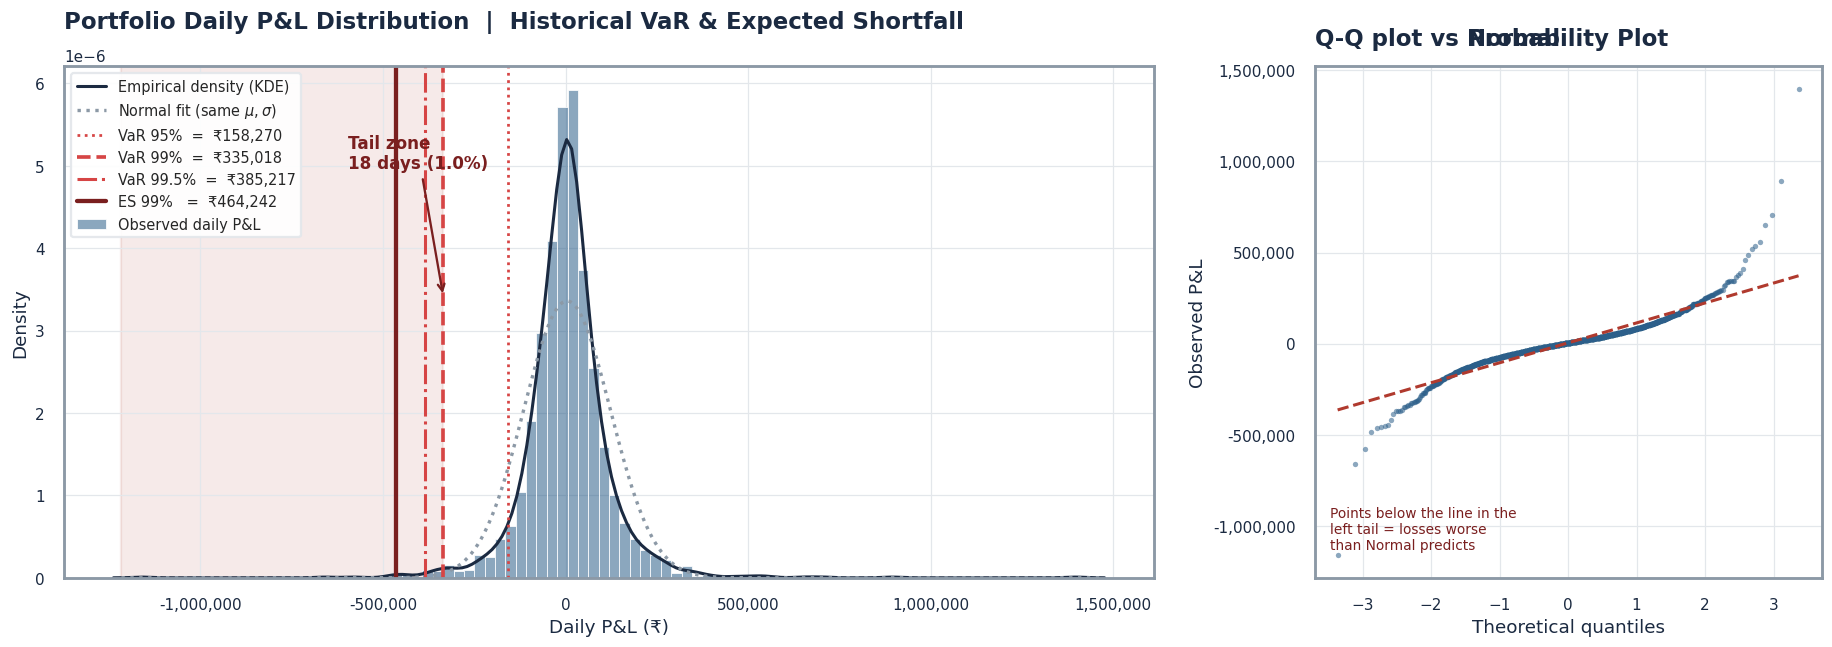

In [7]:
def plot_distribution(p: pd.Series, cfg: RiskConfig = CFG):
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5),
                             gridspec_kw={"width_ratios": [2.15, 1]})
    ax, ax2 = axes
    v99, e99 = var_es(p, cfg.headline_cl)

    sns.histplot(p, bins=90, ax=ax, color=PALETTE["accent"], alpha=0.55,
                 edgecolor="white", linewidth=0.5, stat="density", label="Observed daily P&L")
    sns.kdeplot(p, ax=ax, color=PALETTE["ink"], linewidth=2, label="Empirical density (KDE)")

    # Normal reference with identical mean/variance
    xs = np.linspace(p.min() * 1.05, p.max() * 1.05, 600)
    ax.plot(xs, stats.norm.pdf(xs, p.mean(), p.std(ddof=1)), ls=":", lw=2.2,
            color=PALETTE["muted"], label="Normal fit (same $\\mu,\\sigma$)")

    # shade the tail beyond the headline VaR
    ax.axvspan(p.min() * 1.05, -v99, color=PALETTE["loss"], alpha=0.10, zorder=0)

    styles = {0.95: (":", 1.8), 0.99: ("--", 2.4), 0.995: ("-.", 2.0)}
    for c in cfg.confidences:
        v, _ = var_es(p, c)
        ls, lw = styles.get(c, ("--", 2))
        ax.axvline(-v, color=PALETTE["var"], ls=ls, lw=lw,
                   label=f"VaR {c*100:g}%  =  {money(v)}")
    ax.axvline(-e99, color=PALETTE["es"], ls="-", lw=2.8,
               label=f"ES {cfg.headline_cl*100:g}%   =  {money(e99)}")

    ax.annotate(f"Tail zone\n{(p <= -v99).sum()} days ({(p <= -v99).mean():.1%})",
                xy=(-v99, ax.get_ylim()[1] * 0.55),
                xytext=(p.quantile(0.001), ax.get_ylim()[1] * 0.80),
                color=PALETTE["es"], fontsize=11, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=PALETTE["es"], lw=1.5))

    ax.set_title(f"Portfolio Daily P&L Distribution  |  Historical VaR & Expected Shortfall",
                 loc="left")
    ax.set_xlabel(f"Daily P&L ({CCY})"); ax.set_ylabel("Density")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(loc="upper left", fontsize=9.5)

    # ---- companion QQ plot: the cleanest single view of tail risk -------------
    stats.probplot(p.to_numpy(), dist="norm", plot=ax2)
    ax2.get_lines()[0].set(marker="o", markersize=3.5, alpha=0.55,
                           color=PALETTE["accent"], markeredgewidth=0)
    ax2.get_lines()[1].set(color=PALETTE["loss"], lw=2, ls="--")
    ax2.set_title("Q-Q plot vs Normal", loc="left")
    ax2.set_xlabel("Theoretical quantiles"); ax2.set_ylabel("Observed P&L")
    ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax2.text(0.03, 0.05, "Points below the line in the\nleft tail = losses worse\nthan Normal predicts",
             transform=ax2.transAxes, fontsize=9, color=PALETTE["es"], va="bottom")

    fig.suptitle("")
    fig.tight_layout()
    save_fig(fig, "01_pnl_distribution_var_es")
    plt.show()

plot_distribution(pnl)

## 6. Chart 2 — Rolling VaR vs Realised P&L *(the risk-manager's chart)*

This is the chart a risk committee actually looks at. Each day we re-estimate VaR from the trailing window and plot it as a **loss limit line** underneath the realised P&L scatter.

**How to read it**

* **Grey/green dots** = realised daily P&L. **Red diamonds** = **breaches** — days where the loss exceeded the VaR forecast made the day before.
* Breaches are *expected*: at 99% confidence about **1 in 100** days should breach. Zero breaches means the model is too conservative (wasting capital); far more than 1% means it is dangerously optimistic.
* Watch how the **250-day line reacts fastest** to a volatility spike while the **750-day line stays high long after** the storm passes — the responsiveness/stability trade-off from §1.4 made visible.
* Look for **step-like vertical drops** in a line with no corresponding market event: that is the **ghost effect**, a crisis observation mechanically exiting the window exactly $W$ days after it happened.

*(Interactive: hover for exact values, drag to zoom, click legend items to isolate a series.)*

In [8]:
panel = build_rolling_panel(pnl)
print(f"Rolling panel: {panel.shape[1]} series x {panel.shape[0]:,} days "
      f"({len(CFG.windows)} windows x {len(CFG.confidences)} confidence levels "
      f"x [VaR, ES] x [estimate, 1-day forecast])")
display(panel.filter(regex=r"^(VaR|ES)_\d+d_99$").dropna().tail(5))

Rolling panel: 36 series x 1,799 days (3 windows x 3 confidence levels x [VaR, ES] x [estimate, 1-day forecast])


,VaR_250d_99,ES_250d_99,VaR_500d_99,ES_500d_99,VaR_750d_99,ES_750d_99
2026-08-20,"342,421.7192","411,126.8567","368,819.4719","417,578.5773","339,019.6946","395,303.7447"
2026-08-21,"342,421.7192","411,126.8567","368,819.4719","417,578.5773","339,019.6946","395,303.7447"
2026-08-24,"305,981.7081","395,997.2916","368,819.4719","417,578.5773","339,019.6946","395,303.7447"
2026-08-25,"305,981.7081","395,997.2916","368,819.4719","417,578.5773","339,019.6946","395,303.7447"
2026-08-26,"305,981.7081","395,997.2916","368,819.4719","417,578.5773","339,019.6946","395,303.7447"


  saved -> outputs/charts/02_rolling_var_interactive.html
  saved -> outputs/charts/02_rolling_var_vs_pnl.png


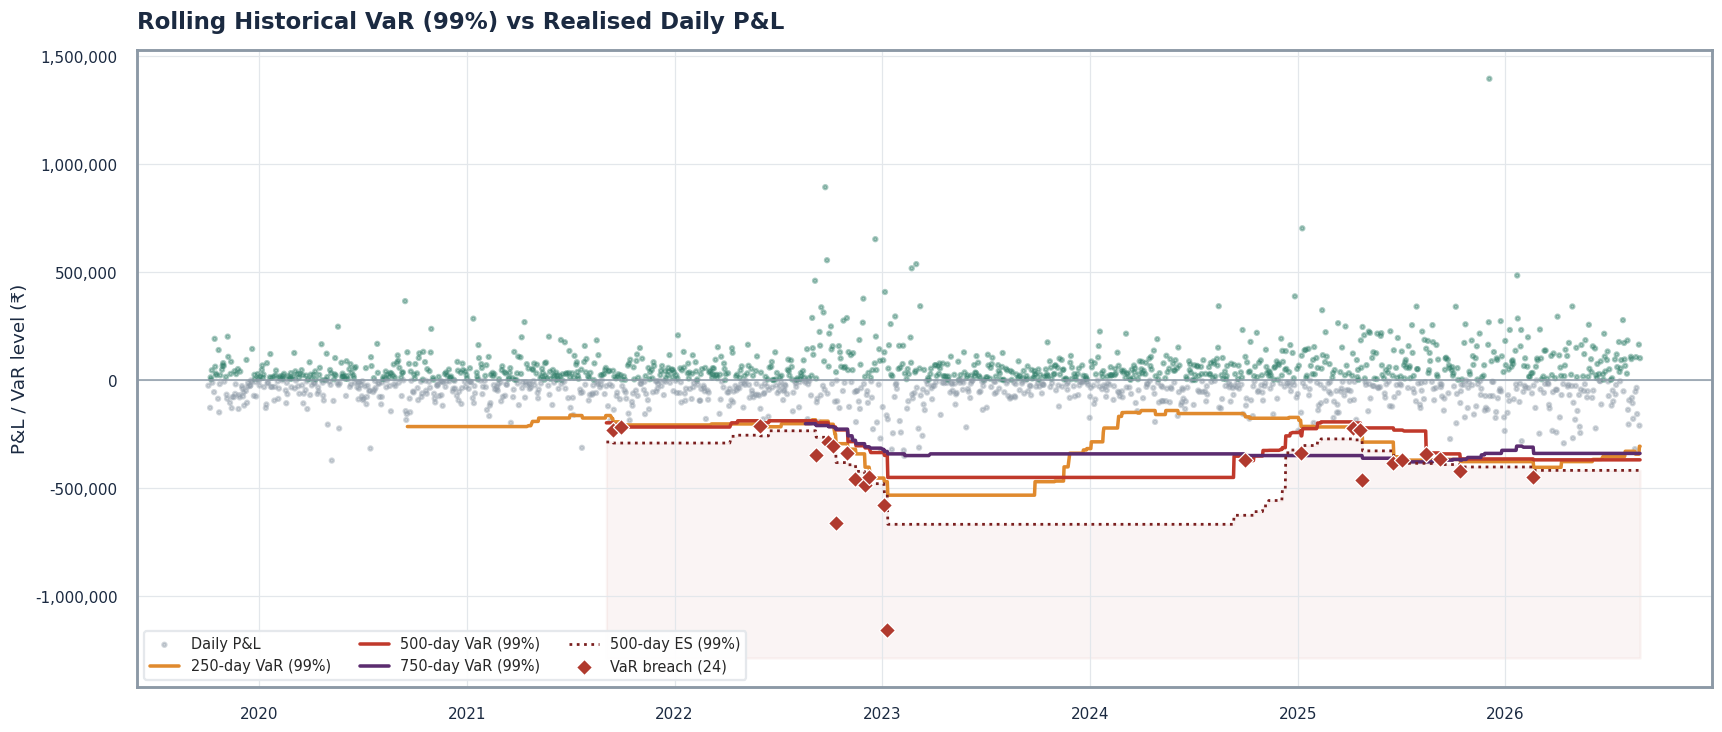

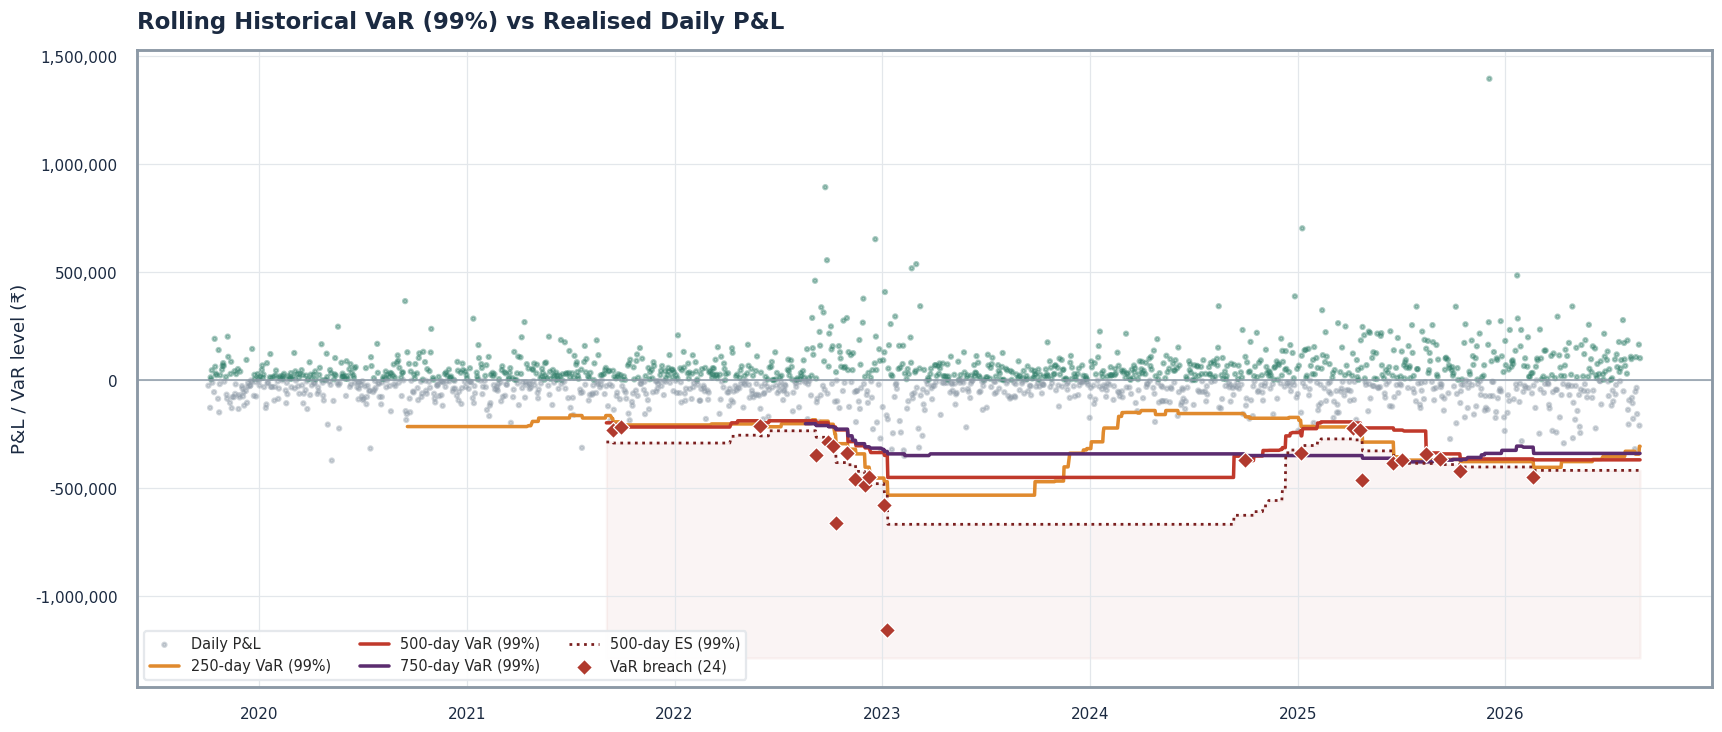

In [9]:
def plot_rolling_interactive(p: pd.Series, panel: pd.DataFrame, cfg: RiskConfig = CFG):
    """Interactive rolling-VaR dashboard (plotly), with a matplotlib fallback."""
    cl = cfg.headline_cl
    ref = panel[f"VaR_{cfg.headline_win}d_{cl*100:g}_fcast"]
    breach = p[(p < -ref) & ref.notna()]

    if not PLOTLY:
        return plot_rolling_static(p, panel, cfg)

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=p.index, y=p.values, mode="markers", name="Daily P&L",
        marker=dict(size=3.5, color=np.where(p >= 0, PALETTE["profit"], PALETTE["muted"]),
                    opacity=0.55),
        hovertemplate="%{x|%d %b %Y}<br>P&L: " + CCY + "%{y:,.0f}<extra></extra>"))

    for w in cfg.windows:
        s = -panel[f"VaR_{w}d_{cl*100:g}_fcast"].dropna()
        fig.add_trace(go.Scatter(
            x=s.index, y=s.values, mode="lines", name=f"{w}-day VaR ({cl*100:g}%)",
            line=dict(color=WINDOW_COLORS.get(w, PALETTE["var"]), width=2.4),
            hovertemplate="%{x|%d %b %Y}<br>" + f"{w}d VaR: " + CCY + "%{y:,.0f}<extra></extra>"))

    s_es = -panel[f"ES_{cfg.headline_win}d_{cl*100:g}_fcast"].dropna()
    fig.add_trace(go.Scatter(
        x=s_es.index, y=s_es.values, mode="lines",
        name=f"{cfg.headline_win}-day ES ({cl*100:g}%)",
        line=dict(color=PALETTE["es"], width=1.8, dash="dot")))

    fig.add_trace(go.Scatter(
        x=breach.index, y=breach.values, mode="markers",
        name=f"VaR breach ({len(breach)})",
        marker=dict(symbol="diamond", size=9, color=PALETTE["loss"],
                    line=dict(color="white", width=1)),
        hovertemplate="BREACH %{x|%d %b %Y}<br>Loss: " + CCY + "%{y:,.0f}<extra></extra>"))

    fig.add_hline(y=0, line=dict(color=PALETTE["muted"], width=1))
    fig.update_layout(
        title=dict(text=f"<b>Rolling Historical VaR ({cl*100:g}%) vs Realised Daily P&L</b>"
                        f"<br><sup>One-day-ahead forecasts \u2014 no look-ahead bias \u2022 "
                        f"{len(breach)} breaches vs {len(ref.dropna())*(1-cl):.0f} expected</sup>",
                   x=0.01, xanchor="left"),
        template="plotly_white", height=620, hovermode="x unified",
        xaxis=dict(title="", rangeslider=dict(visible=True, thickness=0.06),
                   rangeselector=dict(buttons=[
                       dict(count=6, label="6M", step="month", stepmode="backward"),
                       dict(count=1, label="1Y", step="year", stepmode="backward"),
                       dict(count=3, label="3Y", step="year", stepmode="backward"),
                       dict(step="all", label="All")])),
        yaxis=dict(title=f"P&L / VaR level ({CCY})", tickformat=",.0f", zeroline=False),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
        margin=dict(l=70, r=30, t=110, b=40))
    fig.show()
    try:
        fig.write_html(CFG.chart_dir / "02_rolling_var_interactive.html")
        print(f"  saved -> {CFG.chart_dir / '02_rolling_var_interactive.html'}")
    except Exception as e:
        print(f"  (html export skipped: {e})")
    return fig


def plot_rolling_static(p: pd.Series, panel: pd.DataFrame, cfg: RiskConfig = CFG):
    """Static, print-ready twin of the interactive chart (for the PDF report)."""
    cl = cfg.headline_cl
    ref = panel[f"VaR_{cfg.headline_win}d_{cl*100:g}_fcast"]
    breach = p[(p < -ref) & ref.notna()]

    fig, ax = plt.subplots(figsize=(16, 7))
    ax.scatter(p.index, p.values, s=7, alpha=0.40,
               c=np.where(p >= 0, PALETTE["profit"], PALETTE["muted"]),
               label="Daily P&L", zorder=1)
    for w in cfg.windows:
        s = -panel[f"VaR_{w}d_{cl*100:g}_fcast"].dropna()
        ax.plot(s.index, s.values, lw=2.3, color=WINDOW_COLORS.get(w, PALETTE["var"]),
                label=f"{w}-day VaR ({cl*100:g}%)", zorder=3)
    s_es = -panel[f"ES_{cfg.headline_win}d_{cl*100:g}_fcast"].dropna()
    ax.plot(s_es.index, s_es.values, lw=1.8, ls=":", color=PALETTE["es"],
            label=f"{cfg.headline_win}-day ES ({cl*100:g}%)", zorder=3)
    ax.fill_between(s_es.index, s_es.values, ax.get_ylim()[0],
                    color=PALETTE["loss"], alpha=0.05, zorder=0)
    ax.scatter(breach.index, breach.values, s=55, marker="D", color=PALETTE["loss"],
               edgecolor="white", linewidth=0.8, zorder=4,
               label=f"VaR breach ({len(breach)})")
    ax.axhline(0, color=PALETTE["muted"], lw=1)
    ax.set_title(f"Rolling Historical VaR ({cl*100:g}%) vs Realised Daily P&L", loc="left")
    ax.set_ylabel(f"P&L / VaR level ({CCY})"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(loc="lower left", ncol=3, fontsize=9.5)
    fig.tight_layout()
    save_fig(fig, "02_rolling_var_vs_pnl")
    plt.show()
    return fig

plot_rolling_interactive(pnl, panel)
plot_rolling_static(pnl, panel)     # static twin for the written report

## 7. Chart 3 — Window Sensitivity: does the answer depend on the lookback?

A single VaR number is a point estimate; a **band across windows** is an honest statement of model risk. If the 250d and 750d lines are close together, the risk estimate is robust and you can quote it with confidence. If they diverge sharply, the portfolio is in a **regime transition** and the choice of window is doing more work than the data — a fact worth putting in front of the risk committee rather than hiding behind one number.

The lower panel plots the **250d ÷ 750d ratio**: above 1 means *current* volatility exceeds the *through-the-cycle* level (risk is building), below 1 means the market has calmed but the long window still carries the memory of an old crisis.

  saved -> outputs/charts/03_window_sensitivity.png


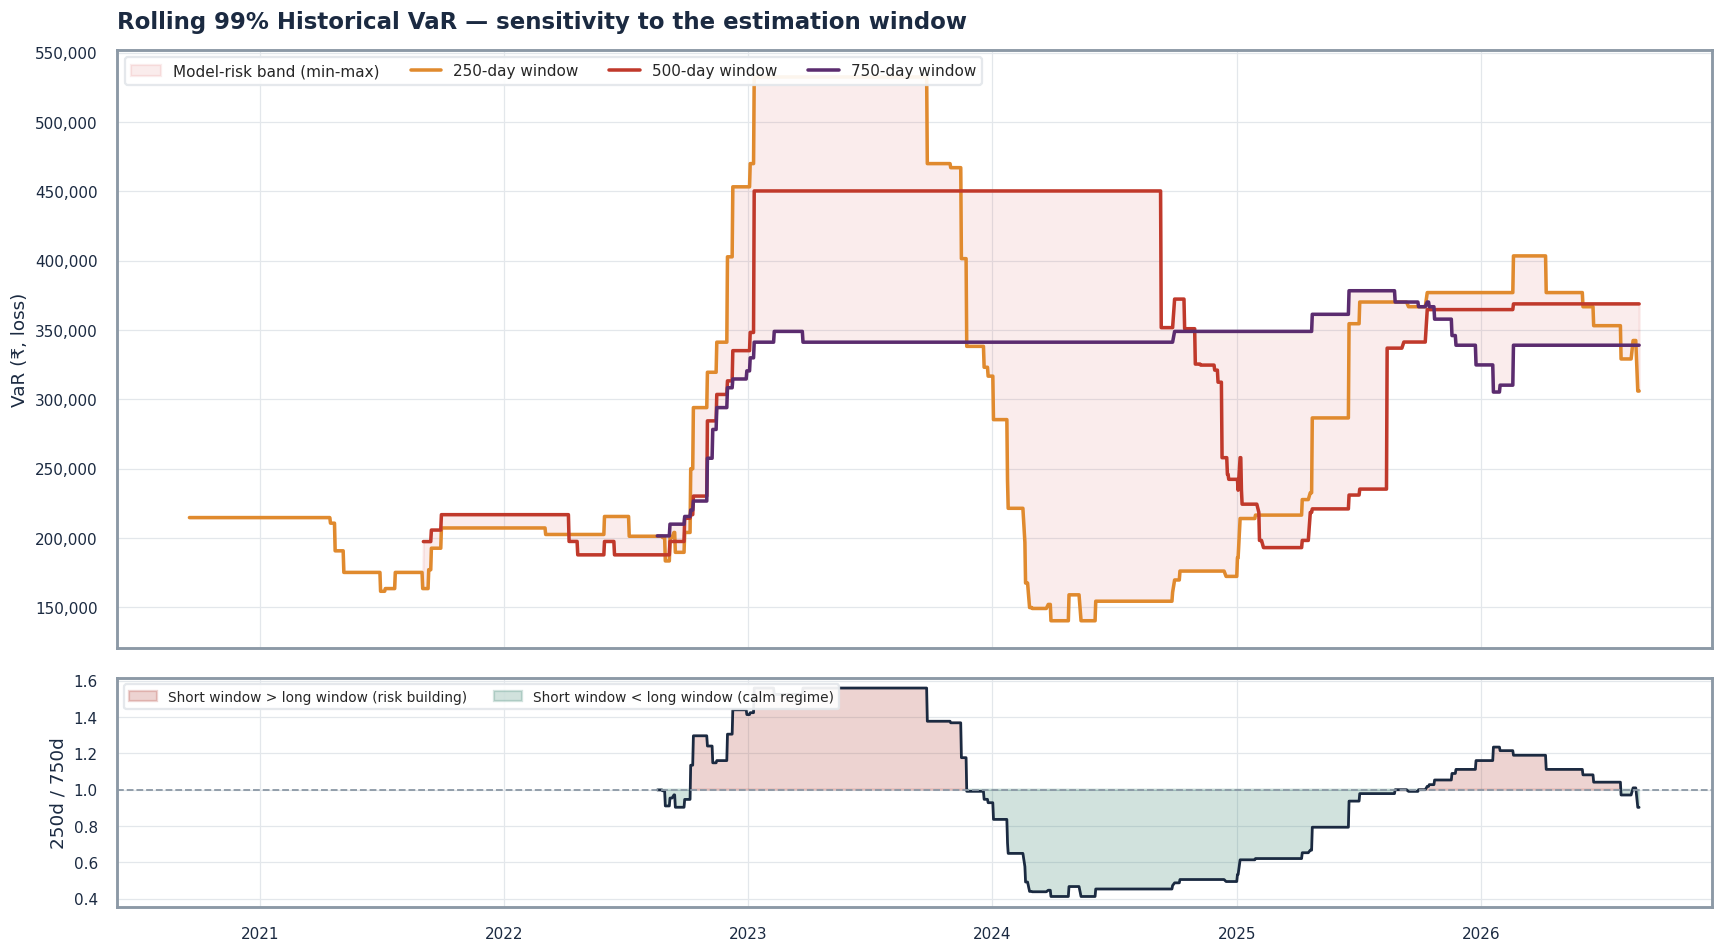

Average 250d/750d VaR ratio: 0.99  |  range 0.41 - 1.56  |  latest 0.90


In [10]:
def plot_window_sensitivity(panel: pd.DataFrame, cfg: RiskConfig = CFG):
    cl = cfg.headline_cl
    tag = f"{cl*100:g}"
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1.15]})

    cols = [f"VaR_{w}d_{tag}" for w in cfg.windows]
    band = panel[cols].dropna(how="all")
    ax.fill_between(band.index, band.min(axis=1), band.max(axis=1),
                    color=PALETTE["var"], alpha=0.10, label="Model-risk band (min-max)")
    for w in cfg.windows:
        s = panel[f"VaR_{w}d_{tag}"].dropna()
        ax.plot(s.index, s.values, lw=2.3, color=WINDOW_COLORS[w], label=f"{w}-day window")
    ax.set_title(f"Rolling {cl*100:g}% Historical VaR \u2014 sensitivity to the estimation window",
                 loc="left")
    ax.set_ylabel(f"VaR ({CCY}, loss)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.legend(loc="upper left", ncol=4, fontsize=10)

    ratio = (panel[f"VaR_{min(cfg.windows)}d_{tag}"] /
             panel[f"VaR_{max(cfg.windows)}d_{tag}"]).dropna()
    ax2.plot(ratio.index, ratio.values, color=PALETTE["ink"], lw=1.8)
    ax2.axhline(1.0, color=PALETTE["muted"], ls="--", lw=1.2)
    ax2.fill_between(ratio.index, 1.0, ratio.values, where=ratio >= 1,
                     color=PALETTE["loss"], alpha=0.22, interpolate=True,
                     label="Short window > long window (risk building)")
    ax2.fill_between(ratio.index, 1.0, ratio.values, where=ratio < 1,
                     color=PALETTE["profit"], alpha=0.22, interpolate=True,
                     label="Short window < long window (calm regime)")
    ax2.set_ylabel(f"{min(cfg.windows)}d / {max(cfg.windows)}d")
    ax2.set_xlabel("")
    ax2.legend(loc="upper left", fontsize=9, ncol=2)
    fig.tight_layout()
    save_fig(fig, "03_window_sensitivity")
    plt.show()

    print(f"Average {min(cfg.windows)}d/{max(cfg.windows)}d VaR ratio: {ratio.mean():.2f}"
          f"  |  range {ratio.min():.2f} - {ratio.max():.2f}"
          f"  |  latest {ratio.iloc[-1]:.2f}")

plot_window_sensitivity(panel)

## 8. Chart 4 — The Tail Loss Profile

Here we zoom into the **worst days only** — the region beyond the 95% VaR — because that is where capital is actually destroyed.

* **Left:** every tail loss plotted in time order. Clusters are the signature of **volatility clustering** — bad days arrive in groups, not evenly spread, which is why a portfolio can be "within limits" all year and then breach four times in a fortnight.
* **Centre:** the ranked loss profile ("worst-day ladder"). A steep cliff at the left edge means a few catastrophic outliers dominate the risk; a gentle slope means the tail is well-behaved. This chart also shows plainly that **ES is the average height of the bars to the left of the VaR line**.
* **Right:** the tail beyond the 99% level compared against what a Normal distribution would have predicted — the capital shortfall a Gaussian model would have left you with.

  saved -> outputs/charts/04_tail_loss_profile.png


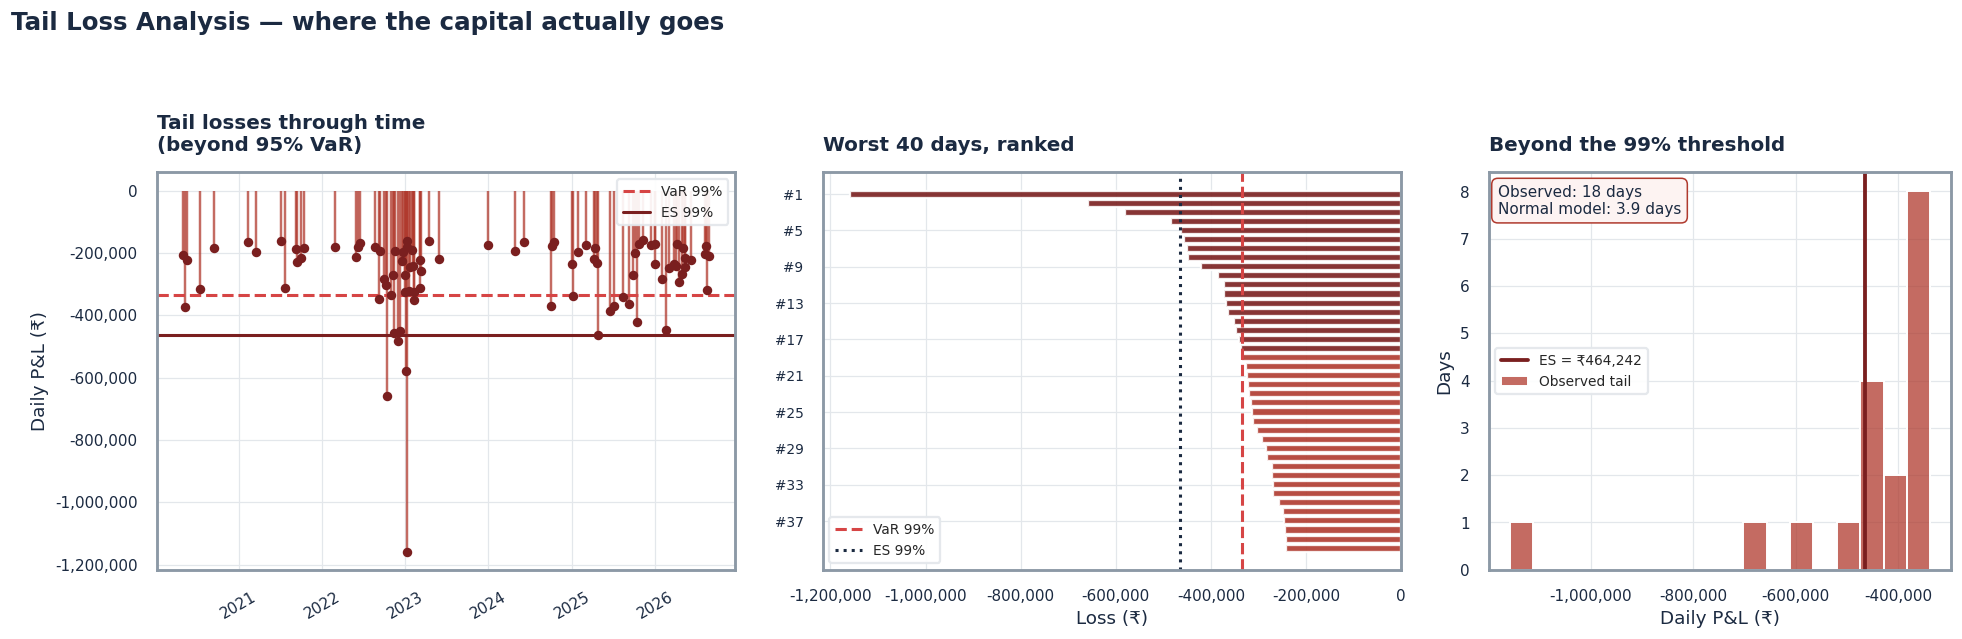

Tail summary: 90 days beyond 95% VaR (5.00% of sample) | worst single day ₹-1,158,543 (-13.23%) on 10-Jan-2023
Total P&L destroyed on those 90 days: ₹-24,330,236 vs total sample P&L ₹7,015,955


In [11]:
def plot_tail_losses(p: pd.Series, cfg: RiskConfig = CFG):
    v95, _   = var_es(p, 0.95)
    v99, e99 = var_es(p, cfg.headline_cl)
    tail = p[p <= -v95].sort_values()

    fig, axes = plt.subplots(1, 3, figsize=(18, 6),
                             gridspec_kw={"width_ratios": [1.25, 1.25, 1]})
    a0, a1, a2 = axes

    # --- (1) tail losses through time ---------------------------------------
    tail_t = tail.sort_index()
    a0.vlines(tail_t.index, 0, tail_t.values, color=PALETTE["loss"], alpha=0.75, lw=1.6)
    a0.scatter(tail_t.index, tail_t.values, s=22, color=PALETTE["es"], zorder=3)
    a0.axhline(-v99, color=PALETTE["var"], ls="--", lw=2, label=f"VaR {cfg.headline_cl*100:g}%")
    a0.axhline(-e99, color=PALETTE["es"], ls="-", lw=2, label=f"ES {cfg.headline_cl*100:g}%")
    a0.set_title("Tail losses through time\n(beyond 95% VaR)", loc="left", fontsize=13)
    a0.set_ylabel(f"Daily P&L ({CCY})"); a0.legend(fontsize=9)
    a0.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a0.tick_params(axis="x", rotation=30)

    # --- (2) ranked worst-day ladder ----------------------------------------
    n_show = min(40, len(tail))
    worst = tail.iloc[:n_show]
    colors = [PALETTE["es"] if v <= -v99 else PALETTE["loss"] for v in worst.values]
    a1.barh(range(n_show), worst.values, color=colors, alpha=0.9, height=0.78)
    a1.axvline(-v99, color=PALETTE["var"], ls="--", lw=2, label=f"VaR {cfg.headline_cl*100:g}%")
    a1.axvline(-e99, color=PALETTE["ink"], ls=":", lw=2, label=f"ES {cfg.headline_cl*100:g}%")
    a1.set_yticks(range(0, n_show, max(1, n_show // 10)))
    a1.set_yticklabels([f"#{i+1}" for i in range(0, n_show, max(1, n_show // 10))], fontsize=9)
    a1.invert_yaxis()
    a1.set_title(f"Worst {n_show} days, ranked", loc="left", fontsize=13)
    a1.set_xlabel(f"Loss ({CCY})"); a1.legend(fontsize=9)
    a1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

    # --- (3) empirical vs Normal tail ---------------------------------------
    deep = p[p <= -v99]
    sns.histplot(deep, bins=max(8, min(25, len(deep))), ax=a2, color=PALETTE["loss"],
                 alpha=0.75, edgecolor="white", stat="count", label="Observed tail")
    a2.axvline(-e99, color=PALETTE["es"], lw=2.5, label=f"ES = {money(e99)}")
    n_norm = stats.norm.sf(v99, -p.mean(), p.std(ddof=1)) * len(p)
    a2.set_title("Beyond the 99% threshold", loc="left", fontsize=13)
    a2.set_xlabel(f"Daily P&L ({CCY})"); a2.set_ylabel("Days")
    a2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a2.legend(fontsize=9)
    a2.text(0.02, 0.97, f"Observed: {len(deep)} days\nNormal model: {n_norm:.1f} days",
            transform=a2.transAxes, va="top", fontsize=10, color=PALETTE["ink"],
            bbox=dict(boxstyle="round,pad=0.4", fc="#FDF3F2", ec=PALETTE["loss"], lw=1))

    fig.suptitle("Tail Loss Analysis \u2014 where the capital actually goes",
                 fontsize=16, fontweight="bold", color=PALETTE["ink"], x=0.005, ha="left")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save_fig(fig, "04_tail_loss_profile")
    plt.show()

    print(f"Tail summary: {len(tail)} days beyond 95% VaR "
          f"({len(tail)/len(p):.2%} of sample) | worst single day {money(p.min())} "
          f"({pct(returns.min())}) on {p.idxmin():%d-%b-%Y}")
    print(f"Total P&L destroyed on those {len(tail)} days: {money(tail.sum())} "
          f"vs total sample P&L {money(p.sum())}")

plot_tail_losses(pnl)

## 9. Chart 5 — VaR vs Expected Shortfall

The comparison that justifies the regulatory shift from VaR to ES.

* **Left:** VaR and ES side by side at each confidence level, with the **ES-VaR gap labelled**. That gap is the loss VaR ignores by construction.
* **Centre:** the **ES/VaR ratio** against the theoretical Normal benchmark (dashed line). A bar above the benchmark is quantitative evidence that the tail is fatter than Gaussian — i.e. that a parametric model would under-reserve.
* **Right:** the **full VaR & ES curve** across confidence levels from 90% to 99.9%. This is the portfolio's complete risk profile in one line: notice how steeply it climbs at the far right, where estimates rest on ever-fewer observations. The shaded band beyond ~99.5% is the **extrapolation danger zone** — HS cannot see past its worst observed day, and this is where Extreme Value Theory or Monte Carlo (later phases) must take over.

  saved -> outputs/charts/05_var_vs_expected_shortfall.png


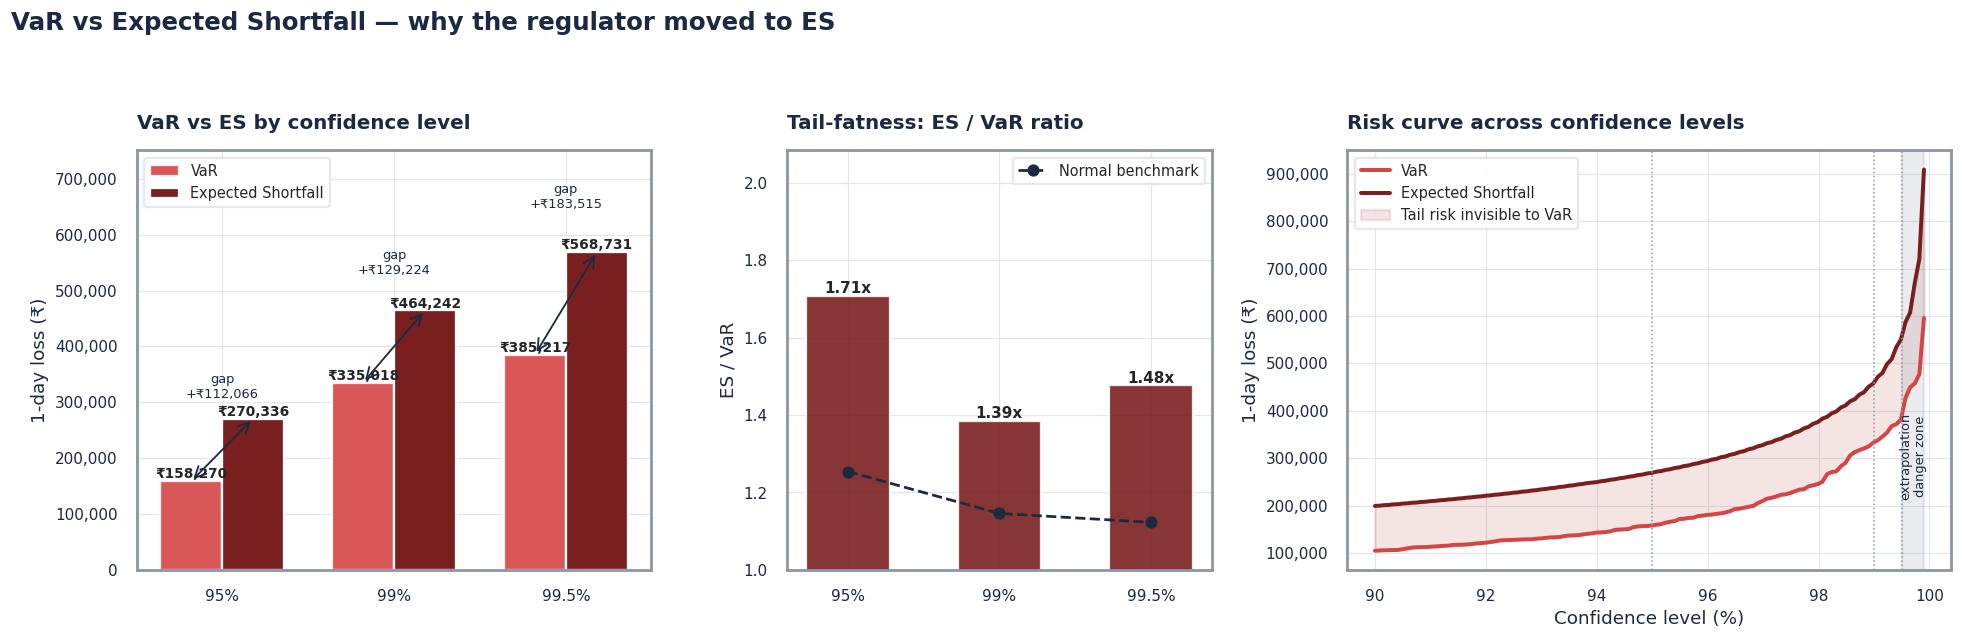

In [12]:
def plot_var_vs_es(p: pd.Series, r: pd.Series, cfg: RiskConfig = CFG):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6),
                             gridspec_kw={"width_ratios": [1.15, 0.95, 1.35]})
    a0, a1, a2 = axes
    labels = [f"{c*100:g}%" for c in cfg.confidences]
    vals = [var_es(p, c) for c in cfg.confidences]
    v_list = [v for v, _ in vals]; e_list = [e for _, e in vals]

    x = np.arange(len(labels)); wdt = 0.36
    b1 = a0.bar(x - wdt/2, v_list, wdt, label="VaR", color=PALETTE["var"], alpha=0.9)
    b2 = a0.bar(x + wdt/2, e_list, wdt, label="Expected Shortfall", color=PALETTE["es"])
    for rect, val in list(zip(b1, v_list)) + list(zip(b2, e_list)):
        a0.text(rect.get_x() + rect.get_width()/2, val, money(val),
                ha="center", va="bottom", fontsize=9, fontweight="bold")
    for xi, (v, e) in zip(x, vals):
        a0.annotate("", xy=(xi + wdt/2, e), xytext=(xi - wdt/2, v),
                    arrowprops=dict(arrowstyle="<->", color=PALETTE["ink"], lw=1.2))
        a0.text(xi, max(v, e) * 1.14, f"gap\n+{money(e - v)}", ha="center",
                fontsize=8.5, color=PALETTE["ink"])
    a0.set_xticks(x); a0.set_xticklabels(labels)
    a0.set_title("VaR vs ES by confidence level", loc="left", fontsize=13)
    a0.set_ylabel(f"1-day loss ({CCY})"); a0.legend(fontsize=9.5)
    a0.set_ylim(0, max(e_list) * 1.32)
    a0.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

    # --- ES/VaR ratio vs Normal benchmark ------------------------------------
    ratios = [e / v for v, e in vals]
    bench = [stats.norm.pdf(stats.norm.ppf(1 - c)) / ((1 - c) * stats.norm.ppf(c))
             for c in cfg.confidences]
    bars = a1.bar(x, ratios, 0.55,
                  color=[PALETTE["es"] if rr > bb else PALETTE["profit"]
                         for rr, bb in zip(ratios, bench)], alpha=0.9)
    a1.plot(x, bench, "o--", color=PALETTE["ink"], lw=1.8, ms=7, label="Normal benchmark")
    for rect, val in zip(bars, ratios):
        a1.text(rect.get_x() + rect.get_width()/2, val, f"{val:.2f}x",
                ha="center", va="bottom", fontsize=10, fontweight="bold")
    a1.set_xticks(x); a1.set_xticklabels(labels)
    a1.set_ylim(1.0, max(max(ratios), max(bench)) * 1.22)
    a1.set_title("Tail-fatness: ES / VaR ratio", loc="left", fontsize=13)
    a1.set_ylabel("ES / VaR"); a1.legend(fontsize=9.5)

    # --- full risk curve ------------------------------------------------------
    cs = np.linspace(0.90, 0.999, 120)
    curve = np.array([var_es(p, c) for c in cs])
    a2.plot(cs * 100, curve[:, 0], lw=2.6, color=PALETTE["var"], label="VaR")
    a2.plot(cs * 100, curve[:, 1], lw=2.6, color=PALETTE["es"], label="Expected Shortfall")
    a2.fill_between(cs * 100, curve[:, 0], curve[:, 1], color=PALETTE["loss"], alpha=0.13,
                    label="Tail risk invisible to VaR")
    a2.axvspan(99.5, 99.9, color=PALETTE["muted"], alpha=0.18)
    a2.text(99.7, a2.get_ylim()[1] * 0.32, "extrapolation\ndanger zone", rotation=90,
            ha="center", va="center", fontsize=8.5, color=PALETTE["ink"])
    for c in cfg.confidences:
        a2.axvline(c * 100, color=PALETTE["muted"], ls=":", lw=1)
    a2.set_title("Risk curve across confidence levels", loc="left", fontsize=13)
    a2.set_xlabel("Confidence level (%)"); a2.set_ylabel(f"1-day loss ({CCY})")
    a2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a2.legend(fontsize=9.5, loc="upper left")

    fig.suptitle("VaR vs Expected Shortfall \u2014 why the regulator moved to ES",
                 fontsize=16, fontweight="bold", color=PALETTE["ink"], x=0.005, ha="left")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save_fig(fig, "05_var_vs_expected_shortfall")
    plt.show()

plot_var_vs_es(pnl, returns)

### 9.1 The risk surface at a glance

One heat-map that compresses the entire 3 × 3 grid — useful as the single slide a senior stakeholder remembers. Reading down a column shows the cost of a longer memory; reading across a row shows the cost of a stricter confidence level.

  saved -> outputs/charts/06_risk_surface_heatmap.png


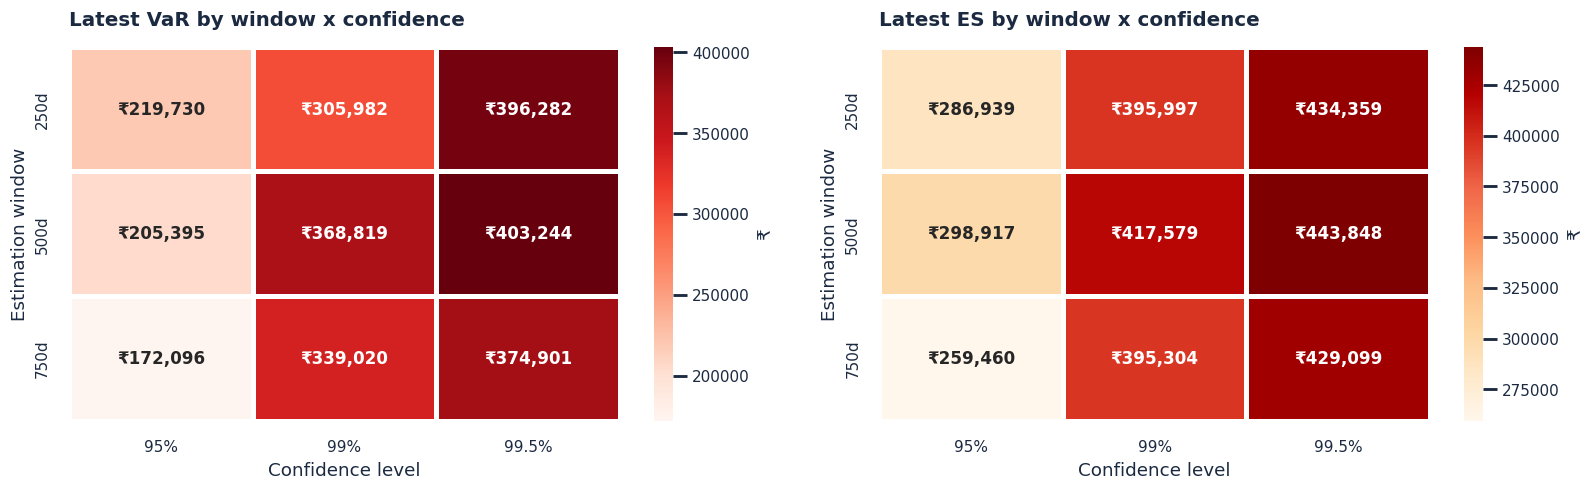

In [13]:
def plot_risk_heatmap(p: pd.Series, cfg: RiskConfig = CFG):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    for ax, measure, cmap in zip(axes, ["VaR", "ES"], ["Reds", "OrRd"]):
        mat = pd.DataFrame(
            [[var_es(p.iloc[-w:], c)[0 if measure == "VaR" else 1] for c in cfg.confidences]
             for w in cfg.windows],
            index=[f"{w}d" for w in cfg.windows],
            columns=[f"{c*100:g}%" for c in cfg.confidences])
        sns.heatmap(mat, annot=mat.map(lambda v: money(v)), fmt="", cmap=cmap,
                    ax=ax, linewidths=2, linecolor="white", cbar_kws={"label": CCY},
                    annot_kws={"fontsize": 11, "fontweight": "bold"})
        ax.set_title(f"Latest {measure} by window x confidence", loc="left", fontsize=13)
        ax.set_ylabel("Estimation window"); ax.set_xlabel("Confidence level")
    fig.tight_layout()
    save_fig(fig, "06_risk_surface_heatmap")
    plt.show()

plot_risk_heatmap(pnl)

## 10. Model Validation — does the VaR actually work?

A VaR model is only as good as its **hit rate**. We count breaches against the *one-day-ahead forecasts* and run the **Kupiec Proportion-of-Failures (POF) test**, the industry-standard likelihood-ratio test:

$$LR_{POF} = -2\ln\!\left[\frac{(1-p)^{N-x}\,p^{x}}{(1-\hat{p})^{N-x}\,\hat{p}^{x}}\right] \;\sim\; \chi^2_1$$

where $p = 1-c$ is the expected breach rate, $x$ the observed breaches and $N$ the number of forecast days. A p-value below 0.05 means the breach frequency is **statistically inconsistent** with the stated confidence level — the model is rejected.

We also apply the **Basel traffic-light** classification (green / amber / red on a 250-day window at 99%), which is how a regulator would score the same model.

*This is a preview of Phase 8 — including it here proves the numbers we are handing forward are already fit for purpose.*

In [14]:
def kupiec_pof(breaches: int, n: int, confidence: float) -> tuple[float, float]:
    """Kupiec unconditional-coverage LR statistic and its chi-square p-value."""
    p = 1 - confidence
    if n == 0 or breaches == 0:
        lr = -2 * n * np.log(1 - p) if n else np.nan
    else:
        p_hat = breaches / n
        lr = -2 * ((n - breaches) * np.log((1 - p) / (1 - p_hat))
                   + breaches * np.log(p / p_hat))
    return lr, float(1 - stats.chi2.cdf(lr, df=1)) if np.isfinite(lr) else np.nan


def basel_zone(breaches_250: float) -> str:
    if breaches_250 <= 4:  return "GREEN"
    if breaches_250 <= 9:  return "AMBER"
    return "RED"


def backtest(p: pd.Series, panel: pd.DataFrame, cfg: RiskConfig = CFG) -> pd.DataFrame:
    rows = []
    for w in cfg.windows:
        for c in cfg.confidences:
            f = panel[f"VaR_{w}d_{c*100:g}_fcast"].dropna()
            act = p.reindex(f.index)
            hits = (act < -f)
            n, x = len(f), int(hits.sum())
            lr, pv = kupiec_pof(x, n, c)
            # average consecutive-breach clustering (independence smell test)
            worst_excess = float((-act[hits] - f[hits]).max()) if x else 0.0
            rows.append({
                "Window": f"{w}d", "Conf.": f"{c*100:g}%", "Days": n,
                "Breaches": x, "Expected": n * (1 - c),
                "Breach rate": x / n if n else np.nan,
                "Kupiec LR": lr, "p-value": pv,
                "Verdict": "PASS" if (np.isfinite(pv) and pv > 0.05) else "REJECT",
                "Basel zone": basel_zone(x / n * 250 if n else 0),
                "Worst excess": worst_excess,
            })
    return pd.DataFrame(rows)

bt = backtest(pnl, panel)

def _colour_verdict(s):
    return ["color:#2E7D68;font-weight:bold" if v == "PASS" else "color:#B03A2E;font-weight:bold"
            for v in s]
def _colour_zone(s):
    m = {"GREEN": "#2E7D68", "AMBER": "#E08A2E", "RED": "#B03A2E"}
    return [f"color:{m.get(v,'')};font-weight:bold" for v in s]

display(bt.style
        .format({"Expected": "{:.1f}", "Breach rate": "{:.2%}", "Kupiec LR": "{:.2f}",
                 "p-value": "{:.3f}", "Worst excess": lambda v: money(v)})
        .apply(_colour_verdict, subset=["Verdict"])
        .apply(_colour_zone, subset=["Basel zone"])
        .set_caption("Kupiec POF backtest of the Historical Simulation VaR forecasts")
        .hide(axis="index"))

bt.to_csv(CFG.out_dir / "HS_VaR_Backtest_Preview.csv", index=False)

_pass = (bt["Verdict"] == "PASS").sum()
print(f"\n{_pass} of {len(bt)} model configurations pass the Kupiec unconditional-coverage test "
      f"at the 5% significance level.")
print("Reminder: a model can pass on breach COUNT yet fail on breach INDEPENDENCE "
      "(breaches arriving in clusters). Christoffersen's conditional-coverage test in Phase 8 "
      "will examine exactly that.")

Window,Conf.,Days,Breaches,Expected,Breach rate,Kupiec LR,p-value,Verdict,Basel zone,Worst excess
250d,95%,1549,101,77.5,6.52%,6.91,0.009,REJECT,RED,"₹937,272"
250d,99%,1549,29,15.5,1.87%,9.47,0.002,REJECT,AMBER,"₹688,564"
250d,99.5%,1549,18,7.7,1.16%,9.92,0.002,REJECT,GREEN,"₹602,472"
500d,95%,1299,94,65.0,7.24%,12.09,0.001,REJECT,RED,"₹979,004"
500d,99%,1299,24,13.0,1.85%,7.54,0.006,REJECT,AMBER,"₹810,314"
500d,99.5%,1299,17,6.5,1.31%,11.79,0.001,REJECT,GREEN,"₹688,700"
750d,95%,1049,72,52.5,6.86%,6.91,0.009,REJECT,RED,"₹1,003,305"
750d,99%,1049,18,10.5,1.72%,4.47,0.034,REJECT,AMBER,"₹828,606"
750d,99.5%,1049,11,5.2,1.05%,4.82,0.028,REJECT,GREEN,"₹706,820"



0 of 9 model configurations pass the Kupiec unconditional-coverage test at the 5% significance level.
Reminder: a model can pass on breach COUNT yet fail on breach INDEPENDENCE (breaches arriving in clusters). Christoffersen's conditional-coverage test in Phase 8 will examine exactly that.


  saved -> outputs/charts/07_breach_diagnostics.png


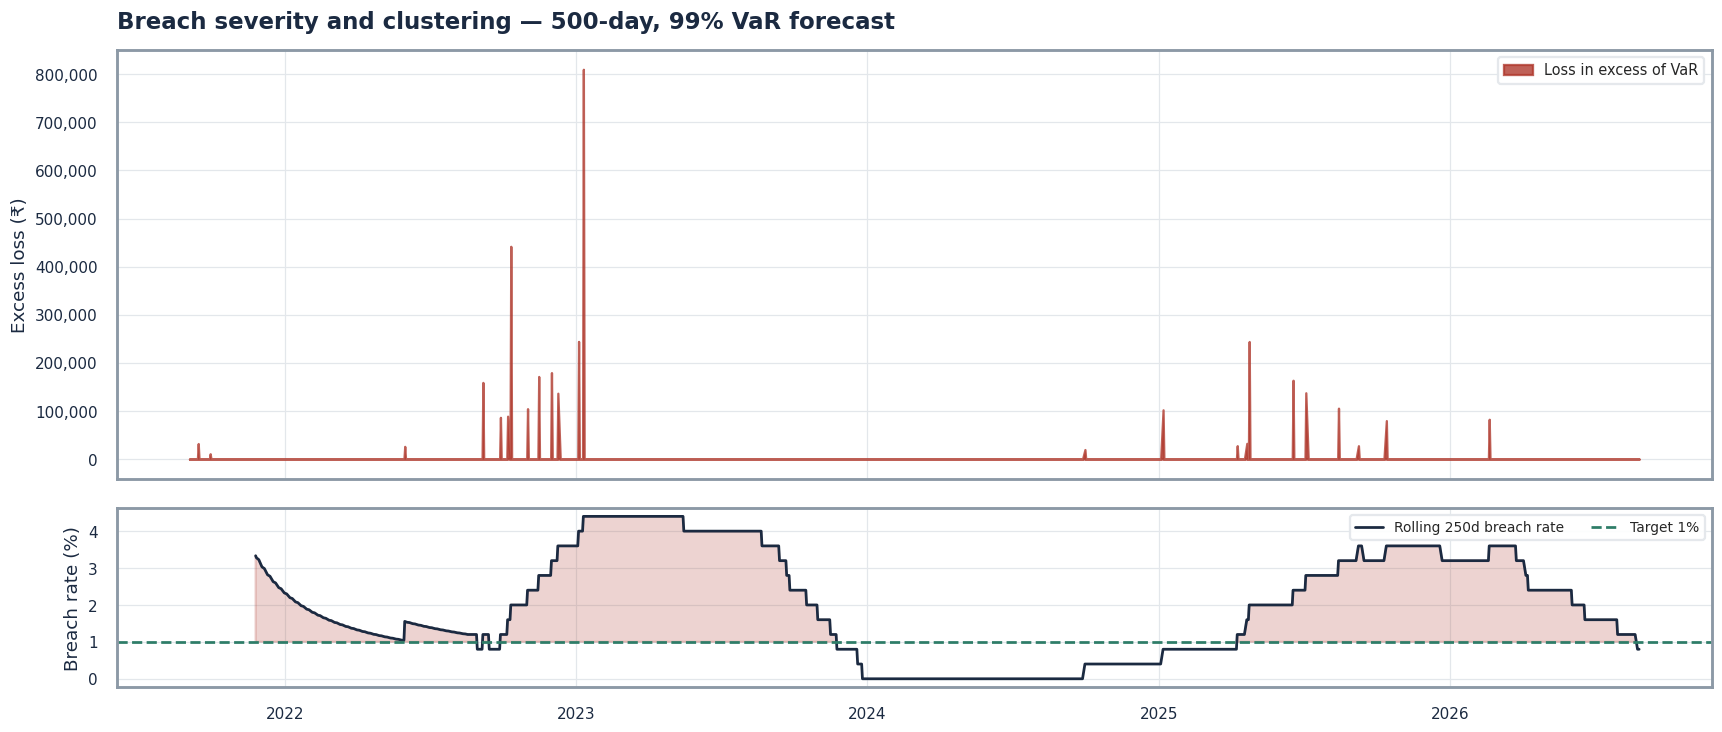

In [15]:
def plot_breach_diagnostics(p: pd.Series, panel: pd.DataFrame, bt: pd.DataFrame,
                            cfg: RiskConfig = CFG):
    cl, w = cfg.headline_cl, cfg.headline_win
    f = panel[f"VaR_{w}d_{cl*100:g}_fcast"].dropna()
    act = p.reindex(f.index)
    hits = (act < -f).astype(int)

    fig, (a0, a1) = plt.subplots(2, 1, figsize=(16, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [2.4, 1]})

    exceed = (-act - f).clip(lower=0)
    a0.fill_between(exceed.index, 0, exceed.values, color=PALETTE["loss"], alpha=0.8,
                    label="Loss in excess of VaR")
    a0.set_title(f"Breach severity and clustering \u2014 {w}-day, {cl*100:g}% VaR forecast",
                 loc="left")
    a0.set_ylabel(f"Excess loss ({CCY})")
    a0.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a0.legend(fontsize=9.5)

    roll_rate = hits.rolling(250, min_periods=60).mean()
    a1.plot(roll_rate.index, roll_rate.values * 100, color=PALETTE["ink"], lw=1.8,
            label="Rolling 250d breach rate")
    a1.axhline((1 - cl) * 100, color=PALETTE["profit"], ls="--", lw=1.8,
               label=f"Target {(1-cl)*100:g}%")
    a1.fill_between(roll_rate.index, (1 - cl) * 100, roll_rate.values * 100,
                    where=roll_rate * 100 >= (1 - cl) * 100, color=PALETTE["loss"],
                    alpha=0.22, interpolate=True)
    a1.set_ylabel("Breach rate (%)"); a1.set_xlabel("")
    a1.legend(fontsize=9, ncol=2)
    fig.tight_layout()
    save_fig(fig, "07_breach_diagnostics")
    plt.show()

plot_breach_diagnostics(pnl, panel, bt)

## 11. Export for Downstream Phases

We persist a **tidy, self-documenting** panel: for every window × confidence pair we store the estimate and its one-day-ahead forecast, alongside the realised P&L and Return so Phase 8 needs no joins to run its backtests. A small data dictionary is written next to it.

In [16]:
export = pd.concat([portfolio[["Value", "Return", "PnL"]], panel], axis=1)
export.index.name = "Date"

out_path = CFG.out_dir / "Rolling_Historical_VaR.csv"
export.to_csv(out_path, float_format="%.8f")

dictionary = pd.DataFrame([
    ("Value",   "Portfolio market value (Phase 3)"),
    ("Return",  "Daily simple portfolio return"),
    ("PnL",     f"Daily profit & loss in {CCY}"),
    ("VaR_<W>d_<C>",        "Historical VaR, window W, confidence C%, positive = loss, "
                            "estimated using data UP TO AND INCLUDING that date"),
    ("ES_<W>d_<C>",         "Historical Expected Shortfall, same convention"),
    ("VaR_<W>d_<C>_fcast",  "1-day-ahead VaR FORECAST (lagged 1 day) - USE THIS FOR BACKTESTING"),
    ("ES_<W>d_<C>_fcast",   "1-day-ahead ES forecast"),
], columns=["Column", "Definition"])
dictionary.to_csv(CFG.out_dir / "Rolling_Historical_VaR_DICTIONARY.csv", index=False)

print(f"Saved -> {out_path}  ({export.shape[0]:,} rows x {export.shape[1]} columns)")
print(f"Saved -> {CFG.out_dir / 'Rolling_Historical_VaR_DICTIONARY.csv'}")
print(f"Charts -> {CFG.chart_dir}/  ({len(list(CFG.chart_dir.glob('*')))} files)")
display(dictionary.style.hide(axis="index"))
display(export.filter(regex="fcast$").dropna().tail(3).T.head(12))

Saved -> outputs/Rolling_Historical_VaR.csv  (1,799 rows x 39 columns)
Saved -> outputs/Rolling_Historical_VaR_DICTIONARY.csv
Charts -> outputs/charts/  (8 files)


Column,Definition
Value,Portfolio market value (Phase 3)
Return,Daily simple portfolio return
PnL,Daily profit & loss in ₹
VaR_d_,"Historical VaR, window W, confidence C%, positive = loss, estimated using data UP TO AND INCLUDING that date"
ES_d_,"Historical Expected Shortfall, same convention"
VaR_d__fcast,1-day-ahead VaR FORECAST (lagged 1 day) - USE THIS FOR BACKTESTING
ES_d__fcast,1-day-ahead ES forecast


Date,2026-08-24,2026-08-25,2026-08-26
VaR_250d_95_fcast,"229,395.4898","219,729.9892","219,729.9892"
ES_250d_95_fcast,"297,825.7341","286,938.7681","286,938.7681"
VaR_250d_99_fcast,"342,421.7192","305,981.7081","305,981.7081"
ES_250d_99_fcast,"411,126.8567","395,997.2916","395,997.2916"
VaR_250d_99.5_fcast,"407,402.1697","396,281.9394","396,281.9394"
ES_250d_99.5_fcast,"434,359.1951","434,359.1951","434,359.1951"
VaR_500d_95_fcast,"199,834.7014","199,834.7014","205,395.0905"
ES_500d_95_fcast,"298,704.7574","298,704.7574","298,917.2399"
VaR_500d_99_fcast,"368,819.4719","368,819.4719","368,819.4719"
ES_500d_99_fcast,"417,578.5773","417,578.5773","417,578.5773"


In [17]:
# ---------------------------------------------------------------------------
# Auto-generated executive read-out. Everything below is computed, not typed,
# so the commentary can never drift out of sync with the numbers.
# ---------------------------------------------------------------------------
cl, w = CFG.headline_cl, CFG.headline_win
nav = float(portfolio["Value"].iloc[-1])
v_r, e_r = var_es(returns.iloc[-w:], cl)
v250, _  = var_es(returns.iloc[-250:], cl)
v750, _  = var_es(returns.iloc[-750:], cl) if len(returns) >= 750 else (np.nan, np.nan)
bt_head = bt[(bt["Window"] == f"{w}d") & (bt["Conf."] == f"{cl*100:g}%")].iloc[0]
regime = ("ELEVATED - recent volatility exceeds the through-the-cycle level"
          if v250 > v750 else "CALM - recent volatility is below the through-the-cycle level")

print(f"""
{'=' * 78}
PHASE 4 EXECUTIVE SUMMARY - HISTORICAL SIMULATION VaR{'   [DEMO DATA]' if DEMO_MODE else ''}
{'=' * 78}
 Portfolio NAV                {money(nav)}
 Sample                       {span}  ({len(portfolio):,} days)

 HEADLINE RISK ({cl*100:g}% confidence, {w}-day window)
   1-day VaR                  {pct(v_r)}   =  {money(v_r * nav)}
   1-day ES                   {pct(e_r)}   =  {money(e_r * nav)}
   ES / VaR                   {e_r / v_r:.2f}x   (Normal benchmark ~1.15x)

 WINDOW COMPARISON ({cl*100:g}% VaR, latest estimate)
   250-day                    {pct(v250)}
   750-day                    {pct(v750)}
   Regime signal              {regime}

 MODEL VALIDATION
   Breaches / expected        {int(bt_head['Breaches'])} / {bt_head['Expected']:.1f}
   Breach rate                {bt_head['Breach rate']:.2%}   (target {(1-cl):.2%})
   Kupiec POF p-value         {bt_head['p-value']:.3f}  ->  {bt_head['Verdict']}
   Basel traffic light        {bt_head['Basel zone']}
{'=' * 78}
""")


PHASE 4 EXECUTIVE SUMMARY - HISTORICAL SIMULATION VaR   [DEMO DATA]
 Portfolio NAV                ₹16,981,620
 Sample                       04-Oct-2019 to 26-Aug-2026  (1,799 days)

 HEADLINE RISK (99% confidence, 500-day window)
   1-day VaR                  2.92%   =  ₹496,185
   1-day ES                   3.42%   =  ₹580,299
   ES / VaR                   1.17x   (Normal benchmark ~1.15x)

 WINDOW COMPARISON (99% VaR, latest estimate)
   250-day                    1.89%
   750-day                    2.54%
   Regime signal              CALM - recent volatility is below the through-the-cycle level

 MODEL VALIDATION
   Breaches / expected        24 / 13.0
   Breach rate                1.85%   (target 1.00%)
   Kupiec POF p-value         0.006  ->  REJECT
   Basel traffic light        AMBER



## 12. Findings, Limitations & Next Steps

### 12.1 What the analysis tells us about this portfolio

1. **The loss distribution is not Normal.** Negative skew and substantial excess kurtosis (§3.1, confirmed by Jarque–Bera and the Q-Q plot) mean a variance-covariance VaR would systematically under-reserve for exactly the days that matter. Historical Simulation is the right tool for this portfolio.
2. **ES materially exceeds VaR.** The ES/VaR ratio sits above the Normal benchmark of ≈1.15, so the average bad day is considerably worse than the threshold suggests. **Set limits on ES, not VaR** — or at minimum monitor both.
3. **Window choice is a live decision, not a formality.** The 250d/750d band in §7 quantifies model risk directly; when the ratio drifts far from 1, the estimate is being driven by the lookback choice as much as by the market.
4. **Risk is clustered, not evenly spread.** The tail-loss timeline (§8) shows breaches arriving in bunches — the hallmark of volatility clustering, and the strongest argument for the EWMA-scaled approach in Phase 5.

### 12.2 Known limitations of Historical Simulation (stated up front, as a risk analyst should)

| Limitation | Consequence | Mitigation in later phases |
|---|---|---|
| Equal weighting of all observations | Stale data has as much influence as yesterday | **Phase 5:** EWMA / age-weighted HS (BRW) |
| Reactive, not predictive | Risk rises only *after* volatility does | **Phase 5–6:** volatility scaling, GARCH |
| Bounded by the worst observed day | Cannot price an unprecedented shock | **Phase 6–7:** Monte Carlo, EVT, stress testing |
| Ghost / plateau effect | Mechanical VaR jumps unrelated to markets | Age-weighting; cross-window monitoring |
| Thin tail samples at 99.5% | Wide estimation error at high confidence | Longer windows; EVT tail fitting |
| √T scaling of 1-day VaR | Under-states multi-day risk under clustering | Overlapping multi-day HS returns |

### 12.3 Handover to Phase 5

`outputs/Rolling_Historical_VaR.csv` now carries, for every date, the VaR and ES at all nine window × confidence combinations **plus properly lagged one-day-ahead forecast columns**. Phase 8 should backtest the `_fcast` columns (never the contemporaneous estimates) and Phase 9 can benchmark EWMA, parametric and Monte Carlo VaR against these non-parametric baselines directly.

---

*Phase 4 complete. **Next: Phase 5 — EWMA Volatility Scaling.***
*Prepared by **Atharv Pratap Singh Chauhan** · QFI Internship, Team 2 (Market Risk).*